# ENTREGABLE 2 — Validación, Análisis Exploratorio y Preparación de Datos

**Proyecto**: Detección de fraude en transacciones con Machine Learning

**Dataset**: IEEE-CIS Fraud Detection (Kaggle, Vesta Corporation + IEEE Computational Intelligence Society)

Este notebook cubre los 8 puntos exigidos por la rúbrica del Entregable 2 y documenta cada etapa del proceso analítico con su interpretación correspondiente.

---
## 1. REVISIÓN DEL PROYECTO

### 1.1 Problema seleccionado
Las pasarelas de pago electrónicas enfrentan fraude transaccional que evoluciona constantemente. Los sistemas actuales basados en reglas estáticas resultan insuficientes para detectar patrones nuevos, generan cuellos de botella operativos y producen falsos positivos.

### 1.2 Pregunta problema
¿Es posible detectar transacciones fraudulentas en pasarelas de pago mediante técnicas de Machine Learning, mejorando la precisión y adaptabilidad respecto a los métodos estáticos actuales?

### 1.3 Objetivo general
Desarrollar un sistema inteligente basado en técnicas de Machine Learning que permita detectar y clasificar transacciones potencialmente fraudulentas en pasarelas de pago, mediante el análisis de características transaccionales y la evaluación del desempeño de diferentes modelos de clasificación.

### 1.4 Objetivos específicos
1. Analizar y caracterizar el conjunto de datos de transacciones para identificar variables relevantes, datos faltantes, valores atípicos y distribución de las clases.
2. Preparar y transformar los datos mediante técnicas de limpieza, tratamiento de valores faltantes y generación de características.
3. Implementar diferentes modelos de Machine Learning para clasificar transacciones.
4. Evaluar el desempeño mediante precisión, recall, F1-score y matriz de confusión.
5. Seleccionar el modelo con mejor desempeño y analizar sus resultados frente a métodos basados en reglas estáticas.

### 1.5 Dataset utilizado
IEEE-CIS Fraud Detection: `train_transaction.csv` (590,540 registros, 394 variables) unido con `train_identity.csv` (144,233 registros, 41 variables) mediante `TransactionID`.

### 1.6 Cambios respecto al Entregable 1
- Se mantiene el problema, pregunta y objetivo definidos previamente.
- Se profundiza en la validación de calidad de datos (duplicados, outliers, consistencia).
- Se amplía el análisis exploratorio con visualizaciones específicas por segmentos.
- Se implementa un pipeline completo de 4 modelos de ML, superando la propuesta inicial.

---
## 2. DESCRIPCIÓN DE LOS DATOS

### 2.1 Fuente
Competencia oficial de Kaggle: **IEEE-CIS Fraud Detection**, publicada por Vesta Corporation y la IEEE Computational Intelligence Society.

### 2.2 Dimensiones
- 590,540 registros
- 434 variables (después de unir las dos tablas)
- ~1.3 GB comprimido, ~2.2 GB en memoria

### 2.3 Variable objetivo
`isFraud`: binaria (1 = fraude, 0 = legítima)

### 2.4 Tabla de variables principales

| Variable | Tipo | Descripción |
|---|---|---|
| TransactionID | Identificador | ID único de transacción |
| isFraud | Binaria (target) | 1 = fraude, 0 = legítima |
| TransactionDT | Numérica (temporal) | Segundos desde una referencia |
| TransactionAmt | Numérica | Monto de la transacción en USD |
| ProductCD | Categórica | Tipo de producto (W, H, C, S, R) |
| card1–card6 | Categóricas | Variables de tarjeta de pago |
| addr1, addr2 | Numéricas | Región y país del comprador |
| dist1, dist2 | Numéricas | Distancias asociadas |
| P_emaildomain, R_emaildomain | Categóricas | Dominios de correo electrónico |
| C1–C14 | Numéricas | Conteos anonimizados de Vesta |
| D1–D15 | Numéricas | Deltas temporales |
| M1–M9 | Categóricas | Indicadores de coincidencia |
| V1–V339 | Numéricas | Variables anonimizadas de Vesta |
| DeviceType, DeviceInfo | Categóricas | Dispositivo desde el cual se originó la transacción |

In [ ]:
# ==============================================================================
# 2.5 CONFIGURACIÓN E IMPORTACIONES
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import gc, os, time, joblib, warnings
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    precision_recall_curve, roc_curve
)

warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10
})

DATA_DIR   = '../data'
OUTPUT_DIR = '../outputs'
FIGS_DIR   = os.path.join(OUTPUT_DIR, 'figs')
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'splits'), exist_ok=True)
os.makedirs(FIGS_DIR, exist_ok=True)

print("=" * 60)
print("VERIFICACION DEL ENTORNO")
print("=" * 60)
print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"XGBoost     : {xgb.__version__}")
print("=" * 60)


def reducir_memoria(df):
    """Reduce uso de memoria convirtiendo float64->float32 e int64->int32."""
    for col in df.columns:
        if df[col].dtype == 'float64':
            df[col] = df[col].astype('float32')
        elif df[col].dtype == 'int64':
            if df[col].max() < 2**31 and df[col].min() > -2**31:
                df[col] = df[col].astype('int32')
    return df


def guardar_fig(nombre):
    """Guarda la figura actual en ../outputs/figs/ y la muestra."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, f'{nombre}.png'), dpi=120, bbox_inches='tight')
    plt.show()

VERIFICACION DEL ENTORNO
NumPy       : 2.4.6
Pandas      : 3.0.6
Scikit-learn: 1.9.1
XGBoost     : 3.2.0


In [ ]:
# ==============================================================================
# 2.6 CARGA Y UNION DE DATOS
# ==============================================================================

t0 = time.time()
train_transaction = pd.read_csv(os.path.join(DATA_DIR, 'train_transaction.csv'))
train_identity    = pd.read_csv(os.path.join(DATA_DIR, 'train_identity.csv'))

print(f"train_transaction: {train_transaction.shape}")
print(f"train_identity   : {train_identity.shape}")

train_transaction = reducir_memoria(train_transaction)
train_identity    = reducir_memoria(train_identity)

df = train_transaction.merge(train_identity, on='TransactionID', how='left')
del train_transaction, train_identity
gc.collect()

print(f"\nMerge: {df.shape}")
print(f"Tiempo: {time.time()-t0:.1f}s")
print(f"Memoria: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

# Etiquetas descriptivas para ProductCD (mejora la legibilidad de los graficos)
product_cd_mapping = {
    'W': 'Webshop', 'H': 'Digital Product', 'C': 'Present Card',
    'S': 'Service', 'R': 'Refund'
}
df['ProductCD_named'] = df['ProductCD'].map(product_cd_mapping).fillna(df['ProductCD'])

train_transaction: (590540, 394)
train_identity   : (144233, 41)

Merge: (590540, 434)
Tiempo: 11.3s
Memoria: 1.74 GB


---
## 3. VALIDACIÓN DE LA CALIDAD DE LOS DATOS

Esta sección examina cuatro dimensiones de la calidad del dataset: valores faltantes, duplicados, valores atípicos y consistencia. Cada una se documenta con evidencia empírica y se justifica la estrategia aplicada.

### 3.1 Datos faltantes

El primer paso consiste en cuantificar la magnitud de los valores faltantes por variable y clasificarlos por rangos. La siguiente celda calcula el total de nulos, el porcentaje por columna y agrupa las variables en cinco categorías según su nivel de faltantes.

In [ ]:
print("=" * 60)
print("3.1 DATOS FALTANTES")
print("=" * 60)

nulos = df.isnull().sum()
nulos_pct = (nulos / len(df)) * 100

rangos = {
    'Sin nulos'      : (nulos_pct == 0).sum(),
    '0-20%'          : ((nulos_pct > 0) & (nulos_pct <= 20)).sum(),
    '20-50%'         : ((nulos_pct > 20) & (nulos_pct <= 50)).sum(),
    '50-80%'         : ((nulos_pct > 50) & (nulos_pct <= 80)).sum(),
    'Mayor a 80%'    : (nulos_pct > 80).sum(),
}
print("\nDistribucion por rango de nulos:")
for rango, cant in rangos.items():
    print(f"  {rango:<15}: {cant:>4} columnas")

print(f"\nTotal de valores faltantes: {nulos.sum():,}")

resumen_nulos = pd.DataFrame({
    'Variable': nulos.index,
    'Nulos': nulos.values,
    'Porcentaje': nulos_pct.round(2).values
}).sort_values('Porcentaje', ascending=False)

print("\nTop 15 variables con mayor porcentaje de nulos:")
display(resumen_nulos.head(15).reset_index(drop=True))

3.1 DATOS FALTANTES

Distribucion por rango de nulos:
  Sin nulos      :   21 columnas
  0-20%          :  162 columnas
  20-50%         :   38 columnas
  50-80%         :  140 columnas
  Mayor a 80%    :   74 columnas

Total de valores faltantes: 115,523,073

Top 15 variables con mayor porcentaje de nulos:


,Variable,Nulos,Porcentaje
0,id_24,585793,99.20
1,id_21,585381,99.13
2,id_07,585385,99.13
3,id_25,585408,99.13
4,id_26,585377,99.13
5,id_08,585385,99.13
6,id_27,585371,99.12
7,id_23,585371,99.12
8,id_22,585371,99.12
9,dist2,552913,93.63


### 3.1.1 Visualización — Top 30 variables con más valores faltantes

El siguiente gráfico ordena las 30 variables con mayor porcentaje de faltantes. Permite identificar visualmente los "bloques" de variables problemáticas: si muchas columnas del mismo prefijo (por ejemplo `id_*` o `dist2`) aparecen agrupadas con porcentajes altos, esto indica que esa familia completa de variables es poco informativa.

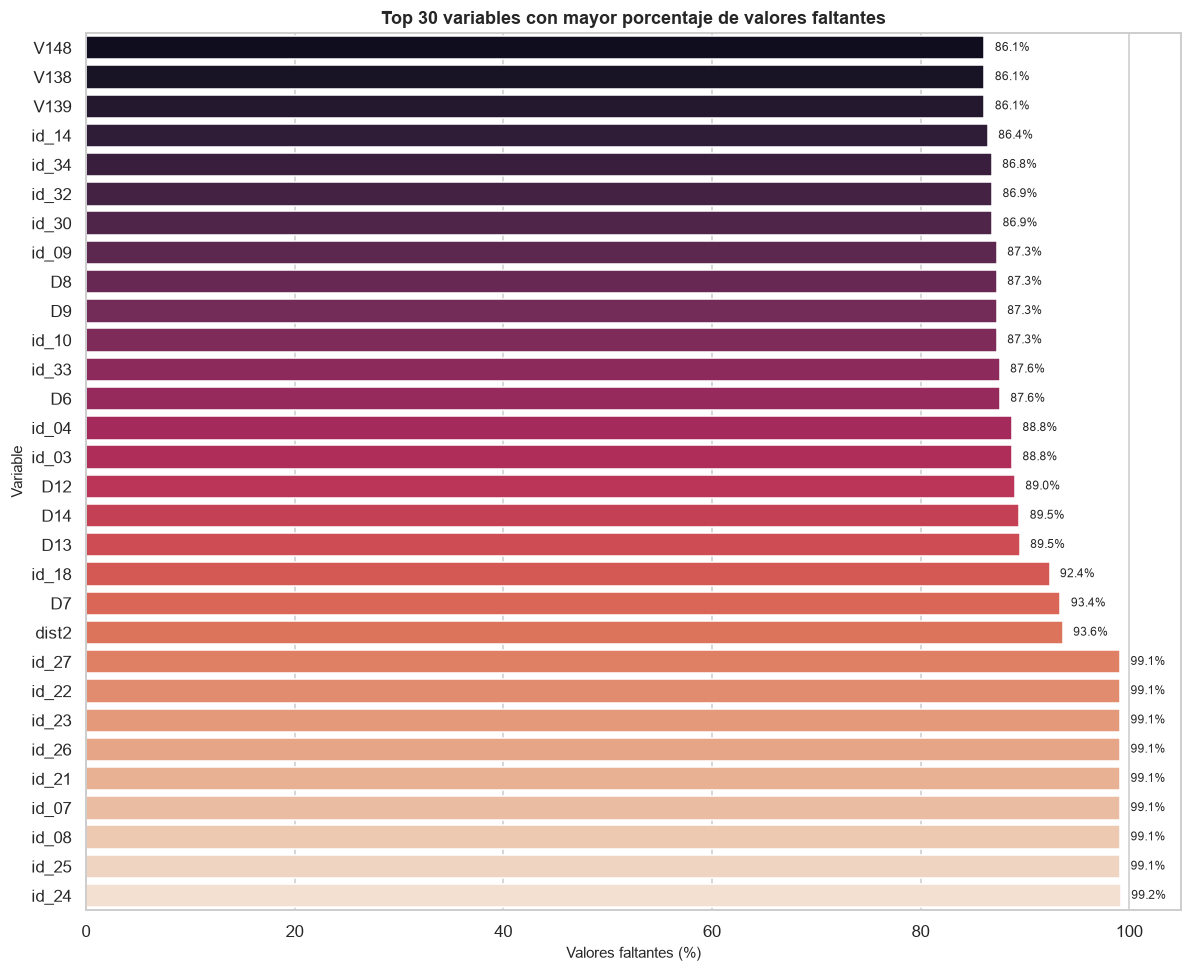

In [ ]:
m = df.isna().mean().mul(100).sort_values(ascending=False).head(30).sort_values()
plt.figure(figsize=(11, 9))
sns.barplot(x=m.values, y=m.index, palette='rocket')
plt.title('Top 30 variables con mayor porcentaje de valores faltantes')
plt.xlabel('Valores faltantes (%)'); plt.ylabel('Variable')
plt.xlim(0, 105)
for i, v in enumerate(m.values):
    plt.text(v + 1, i, f'{v:.1f}%', va='center', fontsize=8)
guardar_fig('01_nulos_top30')

**Interpretación**: la mayoría de las variables con más del 90% de nulos pertenecen a la familia `id_*` (identidad del dispositivo) y `dist2`. Esto es esperado en el dataset IEEE-CIS: solo ~24% de las transacciones tienen información de identidad. Estas columnas serán candidatas a eliminación en la etapa de limpieza.

### 3.1.2 Visualización — Patrón de nulos en muestra de filas

Este mapa de calor muestra, para 100 transacciones aleatorias, qué variables están presentes (celdas blancas) y cuáles faltan (celdas azules). Es útil para detectar si los nulos siguen un patrón estructural (por ejemplo, transacciones sin información de identidad) o si son aleatorios.

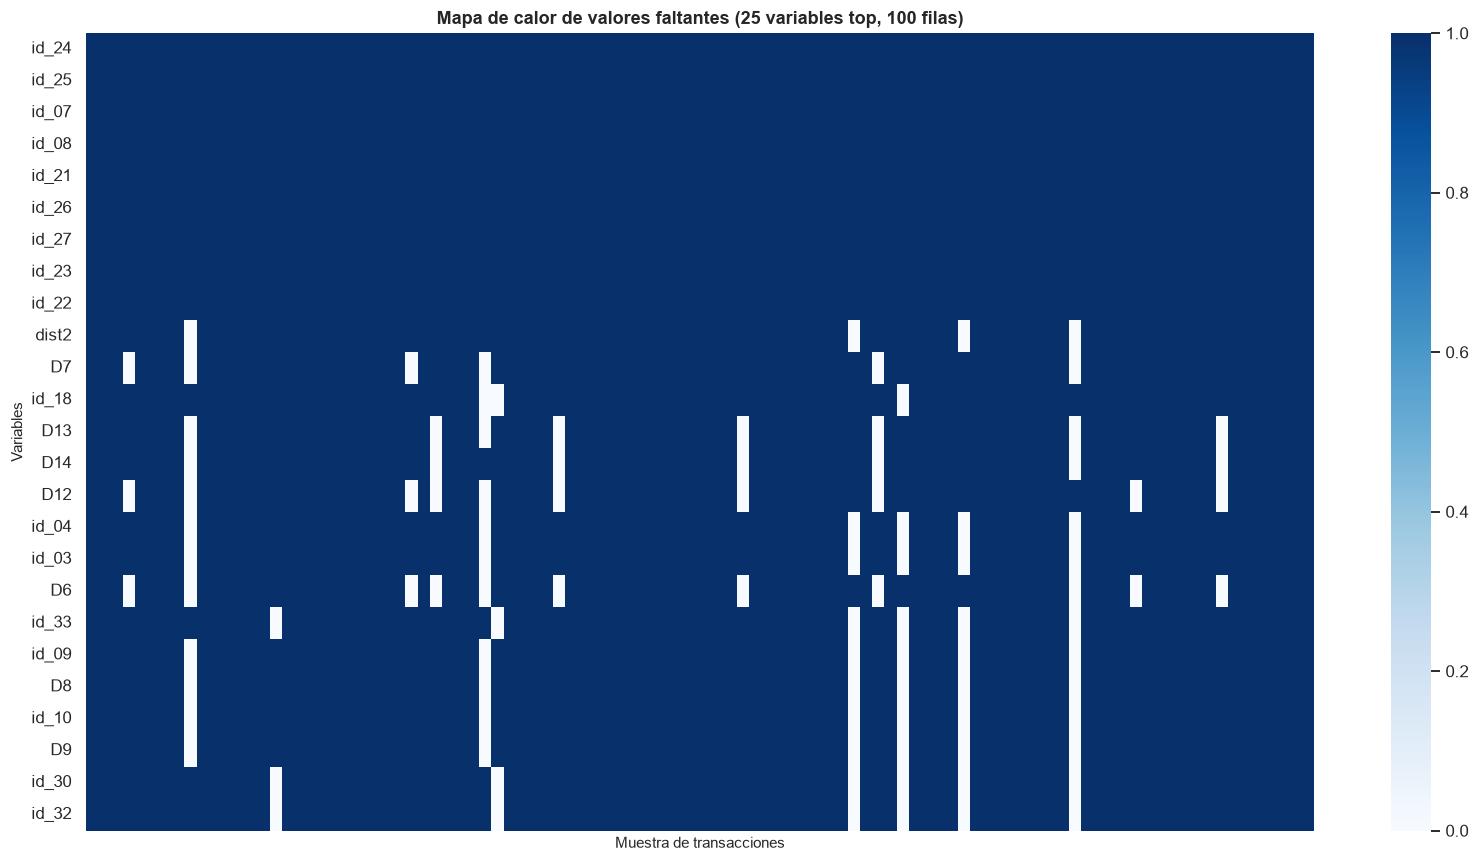

In [ ]:
top = df.isna().mean().sort_values(ascending=False).head(25).index
sample = df[top].isna().sample(n=100, random_state=42).T
plt.figure(figsize=(15, 8))
sns.heatmap(sample, cmap='Blues', cbar=True, yticklabels=True, xticklabels=False, linewidths=0)
plt.title('Mapa de calor de valores faltantes (25 variables top, 100 filas)')
plt.xlabel('Muestra de transacciones'); plt.ylabel('Variables')
guardar_fig('02_nulos_heatmap')

**Interpretación**: se observan franjas horizontales azules continuas, lo que indica que ciertas variables faltan sistemáticamente en subconjuntos de transacciones (probablemente las que no tienen información de identidad). Esto confirma que los nulos no son aleatorios sino estructurales, y por lo tanto la eliminación o imputación debe considerar esta estructura.

### 3.1.3 Visualización — Distribución de nulos por transacción

El histograma muestra cuántas columnas están vacías en cada transacción individual. Permite detectar si hay registros con muy poca información (que podrían ser problemáticos para el modelo) o si la mayoría tiene una cantidad manejable de nulos.

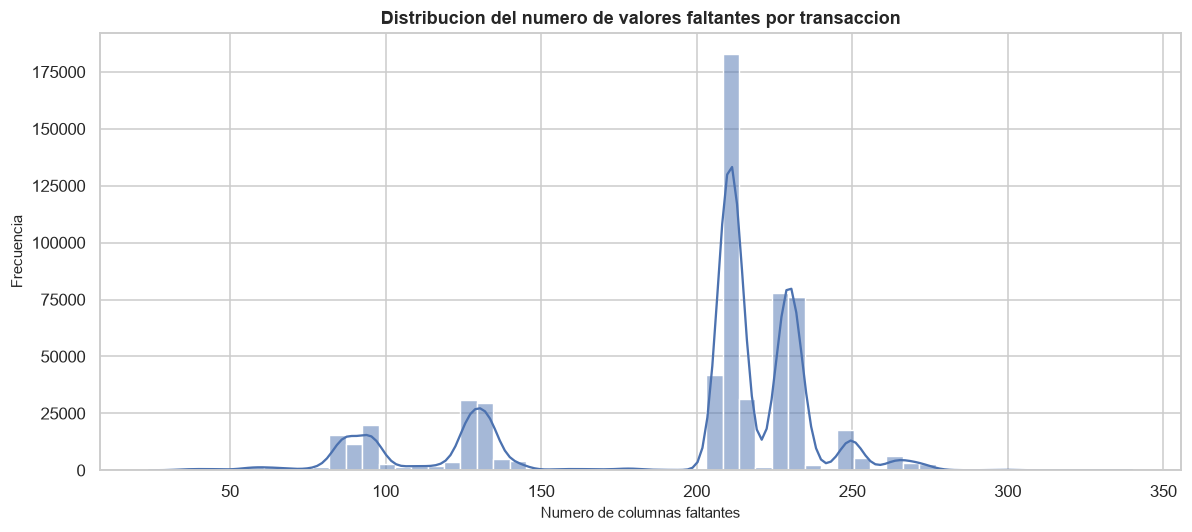

<Figure size 704x528 with 0 Axes>

In [ ]:
row_missing = df.isna().sum(axis=1)
plt.figure(figsize=(11, 5))
sns.histplot(row_missing, bins=60, kde=True, color='#4C72B0')
plt.title('Distribucion del numero de valores faltantes por transaccion')
plt.xlabel('Numero de columnas faltantes'); plt.ylabel('Frecuencia')
plt.tight_layout(); plt.show()
guardar_fig('03_nulos_por_fila')

**Interpretación**: la distribución es bimodal, con un pico en valores bajos (~20-50 nulos) y otro en valores altos (~300 nulos). El segundo pico corresponde a transacciones sin información de identidad asociada. Este patrón confirma la naturaleza estructural de los nulos y justifica no eliminar filas completas, sino columnas específicas.

**Estrategia de tratamiento de nulos:**
1. **Eliminar** columnas con más del 80% de nulos: la imputación en columnas casi vacías introduce ruido.
2. **Imputar con mediana** en variables numéricas: la mediana es robusta frente a valores extremos.
3. **Imputar con moda** en variables categóricas: es la única medida de tendencia central válida para categorías.

Justificación: se evita la pérdida de registros completos, se preserva la distribución original y se usan métodos robustos frente a la alta asimetría de las variables financieras.

### 3.2 Datos duplicados

Se verifican dos tipos de duplicados: filas completamente idénticas y duplicados a nivel de identificador único. Adicionalmente, se examina si hay "clientes recurrentes" (misma tarjeta en varias transacciones legítimas), lo cual no es un error.

In [ ]:
print("=" * 60)
print("3.2 DATOS DUPLICADOS")
print("=" * 60)

dup_filas = df.duplicated().sum()
print(f"\nFilas completamente duplicadas : {dup_filas:,} ({dup_filas/len(df)*100:.4f}%)")

dup_id = df['TransactionID'].duplicated().sum()
print(f"TransactionID duplicados       : {dup_id:,}")

clientes_recurrentes = df['card1'].value_counts()
print(f"\nTarjetas con multiples transacciones: {(clientes_recurrentes > 1).sum():,}")
print(f"  Promedio de transacciones por tarjeta: {clientes_recurrentes.mean():.1f}")
print("\nConclusion: no hay duplicados exactos.")
print("Las repeticiones de card1 corresponden a clientes recurrentes legitimos.")

3.2 DATOS DUPLICADOS

Filas completamente duplicadas : 0 (0.0000%)
TransactionID duplicados       : 0

Tarjetas con multiples transacciones: 10,109
  Promedio de transacciones por tarjeta: 43.6

Conclusion: no hay duplicados exactos.
Las repeticiones de card1 corresponden a clientes recurrentes legitimos.


**Interpretación**: el dataset no contiene duplicados exactos ni duplicados a nivel de `TransactionID`. Las múltiples apariciones de un mismo valor en `card1` reflejan que ese campo no es el número de tarjeta individual sino un identificador de emisor (BIN). No se requiere eliminar registros.

### 3.3 Valores atípicos

Se aplica el método del rango intercuartílico (IQR) sobre las principales variables numéricas continuas. Para cada variable se calcula:
- **Q1** y **Q3**: primer y tercer cuartil.
- **IQR** = Q3 - Q1.
- **Límites**: Q1 - 1.5·IQR y Q3 + 1.5·IQR.
- **Número y porcentaje** de valores fuera de esos límites.

In [ ]:
print("=" * 60)
print("3.3 VALORES ATIPICOS - METODO IQR")
print("=" * 60)


def analizar_outliers_iqr(serie, nombre):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    n_outliers = ((serie < lim_inf) | (serie > lim_sup)).sum()
    pct = n_outliers / len(serie) * 100
    return {
        'Variable': nombre,
        'Q1': round(q1, 2), 'Q3': round(q3, 2), 'IQR': round(iqr, 2),
        'Lim_inf': round(lim_inf, 2), 'Lim_sup': round(lim_sup, 2),
        'N_outliers': n_outliers, '% Outliers': round(pct, 2)
    }


variables_continuas = ['TransactionAmt', 'C1', 'C13', 'C14', 'D1', 'D2', 'D15']
resultados = [analizar_outliers_iqr(df[c].dropna(), c) for c in variables_continuas if c in df.columns]
df_outliers = pd.DataFrame(resultados)
display(df_outliers)

3.3 VALORES ATIPICOS - METODO IQR


,Variable,Q1,Q3,IQR,Lim_inf,Lim_sup,N_outliers,% Outliers
0,TransactionAmt,43.32,125.0,81.68,-79.2,247.52,66482,11.26
1,C1,1.00,3.0,2.00,-2.0,6.00,59535,10.08
2,C13,1.00,12.0,11.00,-15.5,28.50,75631,12.81
3,C14,1.00,2.0,1.00,-0.5,3.50,96090,16.27
4,D1,0.00,122.0,122.00,-183.0,305.00,74185,12.59
5,D2,26.00,276.0,250.00,-349.0,651.00,0,0.00
6,D15,0.00,314.0,314.00,-471.0,785.00,132,0.03


### 3.3.1 Visualización — Boxplots con escala logarítmica

Los boxplots tradicionales se vuelven ilegibles cuando una variable tiene una cola muy larga: el cuerpo del box se comprime y los valores extremos ocupan casi todo el gráfico. Para resolver esto, se aplica **escala logarítmica** al eje Y, lo que hace visibles simultáneamente la mediana, los cuartiles y la extensión de los extremos. Se excluyen los marcadores de outliers (puntos) porque ya fueron cuantificados por IQR en la tabla anterior.

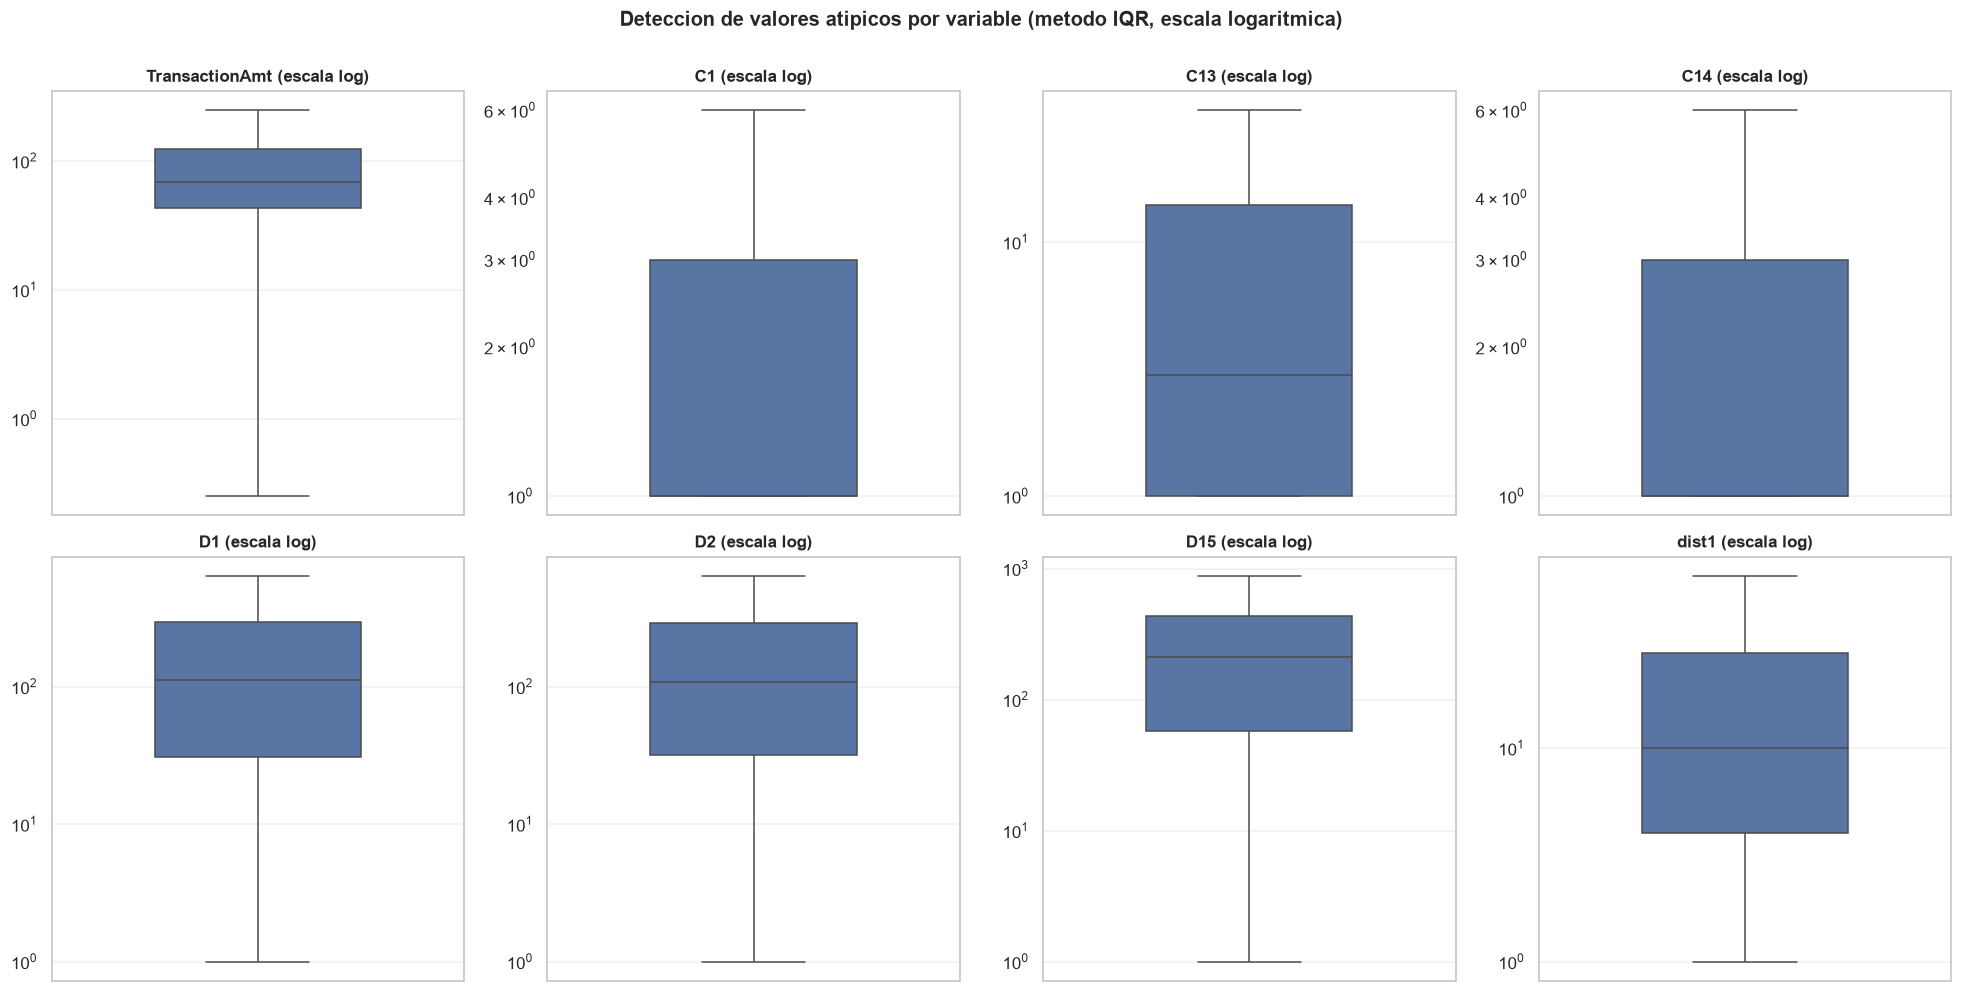

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
cols_plot = ['TransactionAmt', 'C1', 'C13', 'C14', 'D1', 'D2', 'D15', 'dist1']

for ax, col in zip(axes.flatten(), cols_plot):
    if col in df.columns:
        datos = df[col].dropna()
        datos = datos[datos > 0]  # log no admite 0
        if len(datos) > 0:
            sns.boxplot(y=datos, ax=ax, color='#4C72B0', showfliers=False, width=0.5)
            ax.set_yscale('log')
            ax.set_title(f'{col} (escala log)', fontsize=11)
            ax.set_ylabel('')
            ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Deteccion de valores atipicos por variable (metodo IQR, escala logaritmica)',
             fontsize=13, y=1.00, fontweight='bold')
guardar_fig('04_outliers_boxplots')

**Interpretación**: con la escala logarítmica, la caja central (que contiene el 50% de los datos) se hace visible. Se observa que:
- **`TransactionAmt`**: mediana ~69 USD, con cola larga hacia montos altos.
- **`C1`, `C13`, `C14`**: variables de conteo con distribución muy sesgada hacia cero. La mayoría de transacciones tiene conteos bajos, pero unas pocas acumulan miles.
- **`D1`, `D2`, `D15`**: deltas temporales con amplia dispersión; los "bigotes" extendidos indican alta variabilidad.

La presencia de outliers en variables de conteo es esperada: corresponden a tarjetas con muchas transacciones históricas o cuentas de negocio. No se eliminan porque contienen información predictiva.

In [ ]:
# Verificar si los outliers de TransactionAmt son errores o casos validos
limite_sup_amt = df['TransactionAmt'].quantile(0.75) + 1.5 * (
    df['TransactionAmt'].quantile(0.75) - df['TransactionAmt'].quantile(0.25))
outliers_amt  = df[df['TransactionAmt'] > limite_sup_amt]
normales_amt  = df[df['TransactionAmt'] <= limite_sup_amt]

print(f"Tasa de fraude en montos normales: {normales_amt['isFraud'].mean()*100:.2f}%")
print(f"Tasa de fraude en outliers       : {outliers_amt['isFraud'].mean()*100:.2f}%")
print(f"\nUmbral de outlier: ${limite_sup_amt:.2f}")
print(f"Maximo registrado: ${df['TransactionAmt'].max():.2f}")

Tasa de fraude en montos normales: 3.30%
Tasa de fraude en outliers       : 5.07%

Umbral de outlier: $247.52
Maximo registrado: $31937.39


**Decisión sobre outliers**: si la tasa de fraude en los outliers difiere notablemente de la tasa en montos normales, entonces **no son errores sino casos válidos e informativos**. Se conservan y se aplica transformación logarítmica (`log1p`) en la etapa de ingeniería para reducir el efecto de la escala sobre el modelo.

### 3.4 Consistencia de los datos

Se verifica la existencia de valores imposibles, categorías mal escritas, rangos inválidos y fechas inconsistentes. El objetivo es descartar que el dataset contenga errores que invaliden los modelos.

In [ ]:
print("=" * 60)
print("3.4 CONSISTENCIA DE LOS DATOS")
print("=" * 60)

print("\n1. Valores imposibles:")
print(f"   TransactionAmt <= 0 : {(df['TransactionAmt'] <= 0).sum()}")
print(f"   TransactionAmt < 0  : {(df['TransactionAmt'] < 0).sum()}")
print(f"   TransactionDT < 0   : {(df['TransactionDT'] < 0).sum()}")
print(f"   isFraud fuera de {{0,1}}: {((df['isFraud'] != 0) & (df['isFraud'] != 1)).sum()}")

print(f"\n2. Categorias de ProductCD:")
print(df['ProductCD'].value_counts().to_string())

print(f"\n3. Categorias de card6 (tipo de tarjeta):")
print(df['card6'].value_counts(dropna=False).to_string())

print(f"\n4. Categorias de DeviceType:")
print(df['DeviceType'].value_counts(dropna=False).to_string())

print(f"\n5. Rango de TransactionDT:")
print(f"   Min: {df['TransactionDT'].min():,}")
print(f"   Max: {df['TransactionDT'].max():,}")
print(f"   Equivalente a ~{(df['TransactionDT'].max()-df['TransactionDT'].min())/(24*3600):.0f} dias")

3.4 CONSISTENCIA DE LOS DATOS

1. Valores imposibles:
   TransactionAmt <= 0 : 0
   TransactionAmt < 0  : 0
   TransactionDT < 0   : 0
   isFraud fuera de {0,1}: 0

2. Categorias de ProductCD:
ProductCD
W    439670
C     68519
R     37699
H     33024
S     11628

3. Categorias de card6 (tipo de tarjeta):
card6
debit              439938
credit             148986
NaN                  1571
debit or credit        30
charge card            15

4. Categorias de DeviceType:
DeviceType
NaN        449730
desktop     85165
mobile      55645

5. Rango de TransactionDT:
   Min: 86,400
   Max: 15,811,131
   Equivalente a ~182 dias


**Interpretación**: no se detectan valores negativos o cero en `TransactionAmt`, no hay fechas inconsistentes y las categorías de `ProductCD`, `card6` y `DeviceType` son consistentes (no hay variantes de escritura como "Visa"/"visa" o "Credit"/"credit"). El dataset está listo para el preprocesamiento sin requerir correcciones adicionales.

---
## 4. ANÁLISIS EXPLORATORIO DE DATOS (EDA)

### 4.1 Análisis univariado — Variables numéricas

Se calculan las estadísticas descriptivas clásicas para las principales variables numéricas: media, desviación estándar, mínimo, cuartiles y máximo. Estas métricas resumen la tendencia central y la dispersión de cada variable.

In [ ]:
print("=" * 60)
print("4.1 ESTADISTICAS DESCRIPTIVAS - VARIABLES NUMERICAS")
print("=" * 60)

vars_numericas = ['TransactionAmt', 'card1', 'C1', 'C13', 'C14', 'D1', 'D2', 'D15']
vars_presentes = [v for v in vars_numericas if v in df.columns]
display(df[vars_presentes].describe().round(2))

4.1 ESTADISTICAS DESCRIPTIVAS - VARIABLES NUMERICAS


,TransactionAmt,card1,C1,C13,C14,D1,D2,D15
count,590540.00,590540.00,590540.00,590540.00,590540.00,589271.00,309743.00,501427.00
mean,135.03,9898.73,14.09,32.54,8.30,94.35,169.56,163.74
std,239.16,4901.17,133.57,129.36,49.54,157.66,177.32,202.73
min,0.25,1000.00,0.00,0.00,0.00,0.00,0.00,-83.00
25%,43.32,6019.00,1.00,1.00,1.00,0.00,26.00,0.00
50%,68.77,9678.00,1.00,3.00,1.00,3.00,97.00,52.00
75%,125.00,14184.00,3.00,12.00,2.00,122.00,276.00,314.00
max,31937.39,18396.00,4685.00,2918.00,1429.00,640.00,640.00,879.00


### 4.1.1 Visualización — Histogramas de variables numéricas

Los histogramas muestran la distribución de frecuencias de cada variable. En variables con alta asimetría (típico en datos financieros), se recorta a los percentiles P1-P99 para que el patrón sea visible sin que los extremos aplanen el gráfico.

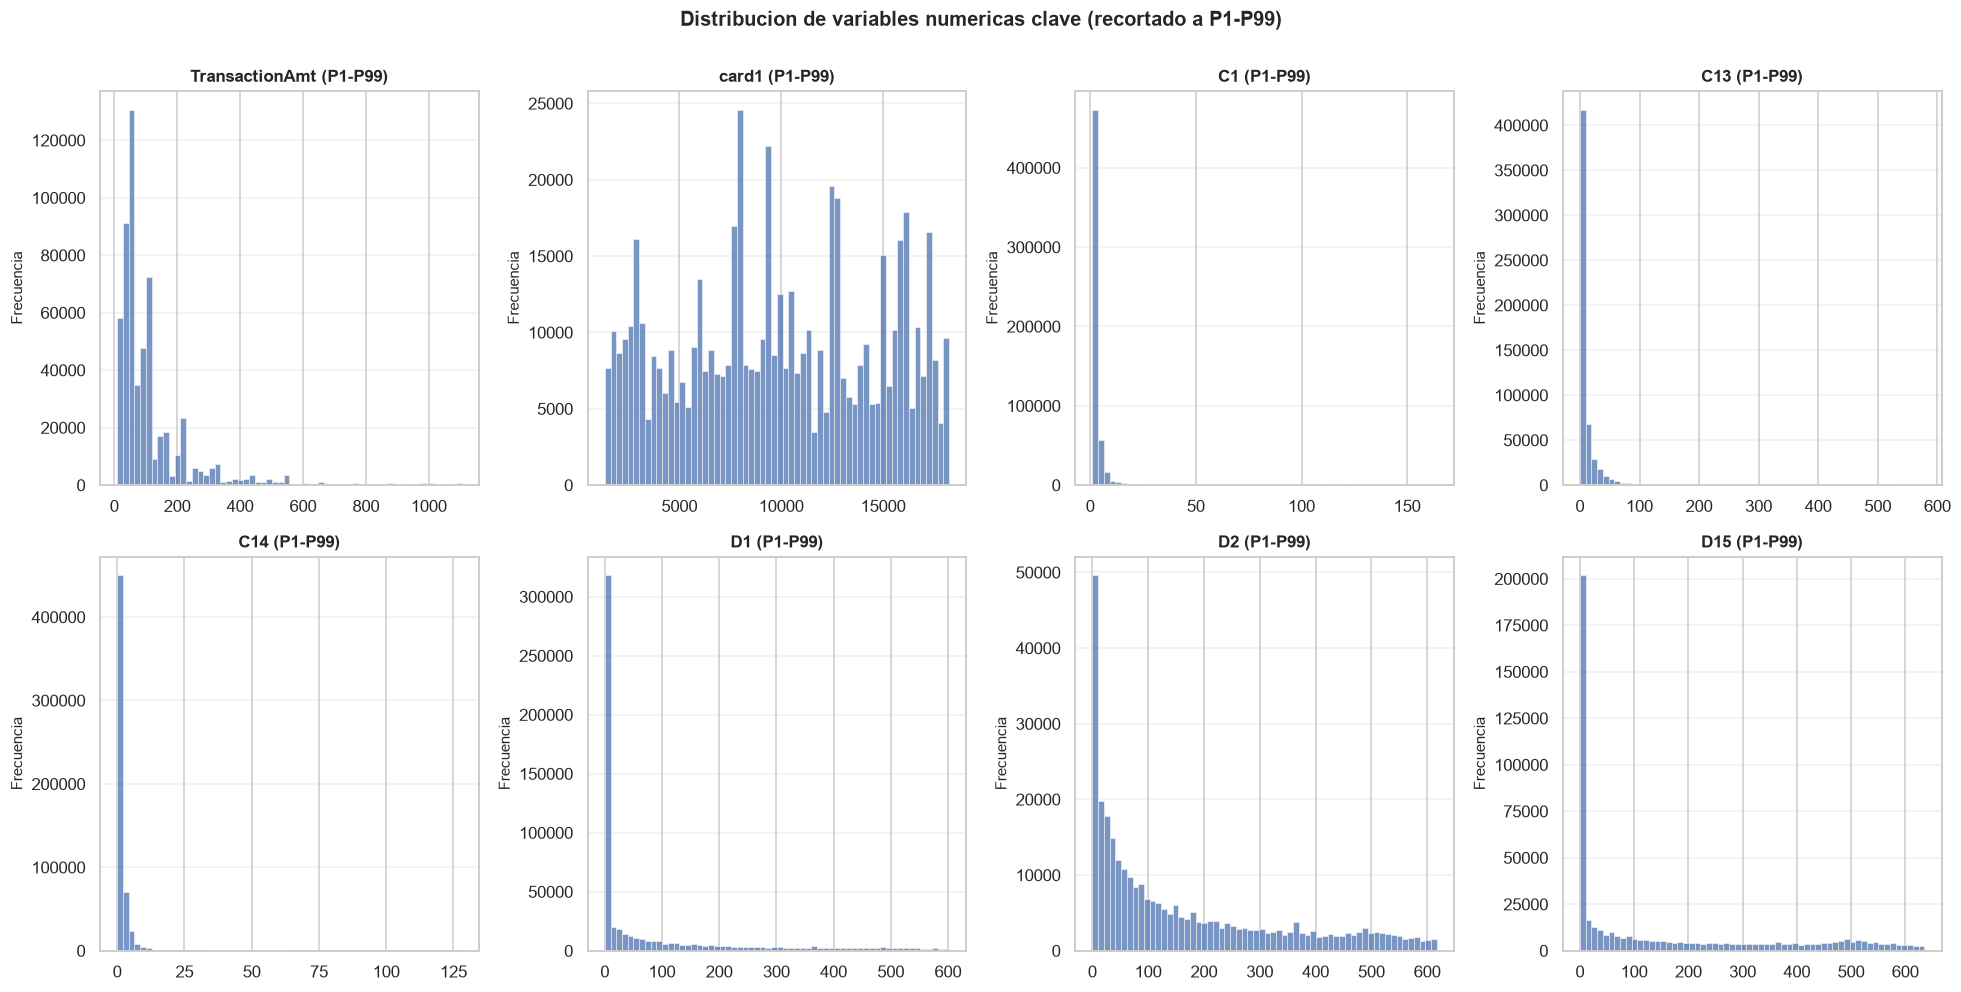

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flatten(), vars_presentes):
    datos = df[col].dropna()
    p1, p99 = datos.quantile([0.01, 0.99])
    datos_recortados = datos[(datos >= p1) & (datos <= p99)]
    sns.histplot(datos_recortados, bins=60, ax=ax, color='#4C72B0')
    ax.set_title(f'{col} (P1-P99)', fontsize=11)
    ax.set_xlabel(''); ax.set_ylabel('Frecuencia')
    ax.grid(True, alpha=0.3, axis='y')
plt.suptitle('Distribucion de variables numericas clave (recortado a P1-P99)',
             fontsize=13, y=1.00, fontweight='bold')
guardar_fig('05_histogramas_numericas')

**Interpretación**: casi todas las variables muestran distribuciones fuertemente sesgadas hacia la derecha (asimetría positiva). `TransactionAmt` concentra la mayor parte de sus valores entre 10 y 200 USD. Las variables `C*` y `D*` presentan picos muy marcados cerca de cero con colas largas. Este patrón justifica el uso de transformaciones logarítmicas y la robustez de modelos basados en árboles (que son invariantes a la escala).

### 4.2 Análisis univariado — Variables categóricas

Se calcula la frecuencia absoluta y relativa de las principales variables categóricas. Esto revela la composición del dataset en cuanto a tipos de producto, marcas de tarjeta, tipo de tarjeta y tipo de dispositivo.

In [ ]:
print("=" * 60)
print("4.2 FRECUENCIAS DE VARIABLES CATEGORICAS")
print("=" * 60)

for col in ['ProductCD_named', 'card4', 'card6', 'DeviceType']:
    if col in df.columns:
        print(f"\n--- {col} ---")
        vc = df[col].value_counts(dropna=False)
        pct = df[col].value_counts(dropna=False, normalize=True) * 100
        resumen = pd.DataFrame({'Frecuencia': vc, 'Porcentaje': pct.round(2)})
        display(resumen.head(10))

4.2 FRECUENCIAS DE VARIABLES CATEGORICAS

--- ProductCD_named ---


,Frecuencia,Porcentaje
ProductCD_named,,
Webshop,439670,74.45
Present Card,68519,11.60
Refund,37699,6.38
Digital Product,33024,5.59
Service,11628,1.97



--- card4 ---


,Frecuencia,Porcentaje
card4,,
visa,384767,65.16
mastercard,189217,32.04
american express,8328,1.41
discover,6651,1.13
NaN,1577,0.27



--- card6 ---


,Frecuencia,Porcentaje
card6,,
debit,439938,74.50
credit,148986,25.23
NaN,1571,0.27
debit or credit,30,0.01
charge card,15,0.00



--- DeviceType ---


,Frecuencia,Porcentaje
DeviceType,,
NaN,449730,76.16
desktop,85165,14.42
mobile,55645,9.42


### 4.2.1 Visualización — Barras de categóricas

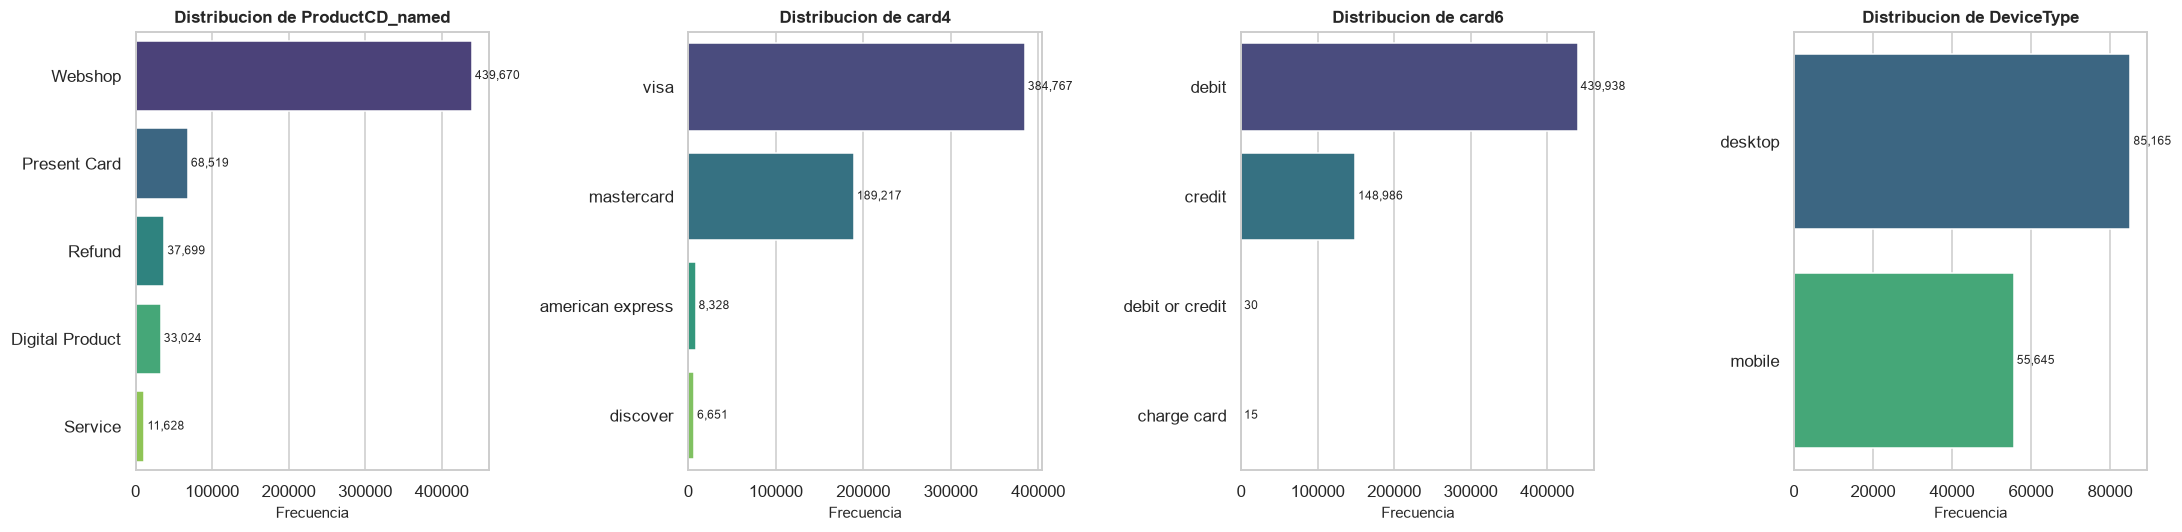

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes.flatten(), ['ProductCD_named', 'card4', 'card6', 'DeviceType']):
    if col in df.columns:
        vc = df[col].value_counts().head(8)
        sns.barplot(x=vc.values, y=vc.index, ax=ax, palette='viridis')
        ax.set_title(f'Distribucion de {col}', fontsize=11)
        ax.set_xlabel('Frecuencia'); ax.set_ylabel('')
        for i, v in enumerate(vc.values):
            ax.text(v, i, f' {v:,}', va='center', fontsize=8)
plt.tight_layout()
guardar_fig('07_barras_categoricas')

**Interpretación**: `Webshop` (W) domina con ~74% de las transacciones, seguido por `Present Card` (C) con ~12%. En cuanto a tarjetas, `visa` y `mastercard` son mayoritarias, mientras que `debit` supera a `credit`. El `DeviceType` está prácticamente balanceado entre `desktop` y `mobile`. Estas distribuciones son relevantes porque la tasa de fraude varía significativamente entre categorías.

---
## 5. RELACIÓN ENTRE VARIABLES

Se examinan las relaciones entre variables numéricas y su asociación con la variable objetivo. Se utilizan tres herramientas: correlaciones, diagramas de dispersión y tablas cruzadas.

### 5.1 Correlación con la variable objetivo

Se calcula la correlación de Pearson entre cada variable numérica y `isFraud`, ordenadas por magnitud absoluta. Valores altos indican asociación lineal fuerte. Se utiliza una muestra del 10% para eficiencia computacional.

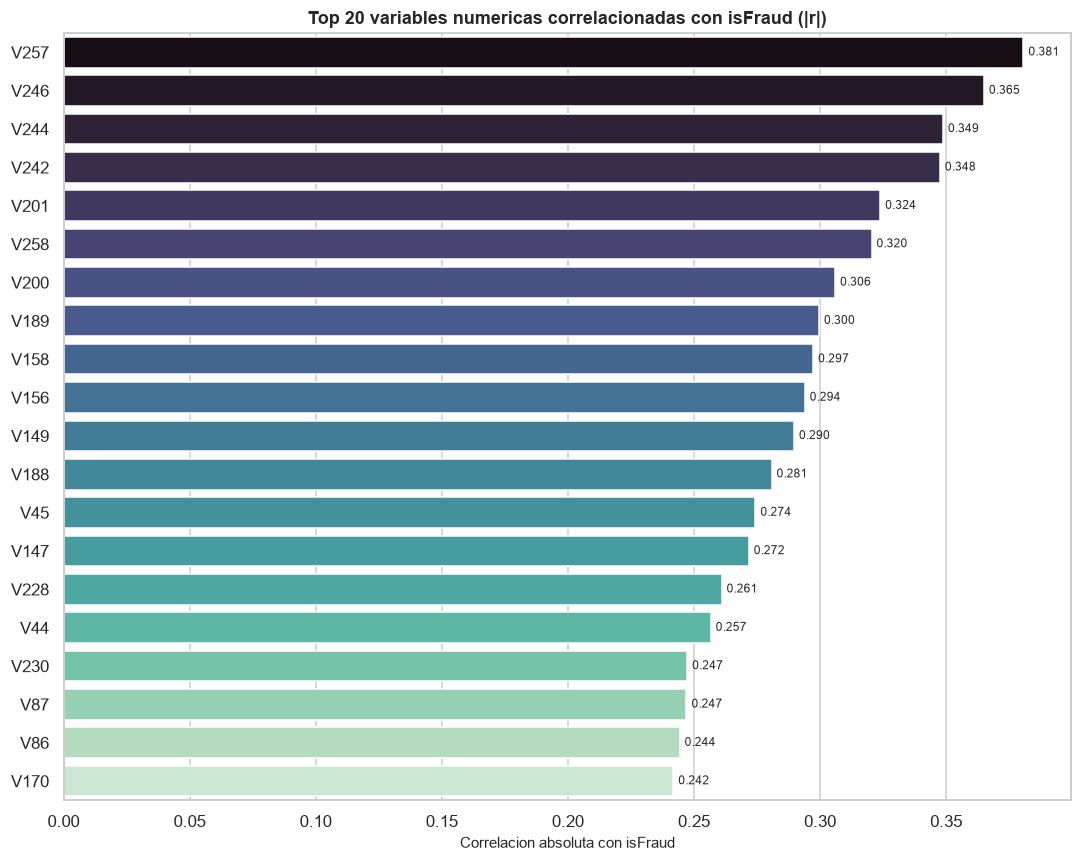

In [ ]:
muestra = df.select_dtypes(include=[np.number]).sample(frac=0.1, random_state=42)
corr_target = muestra.corr()['isFraud'].abs().sort_values(ascending=False).drop('isFraud')
top20 = corr_target.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=top20.values, y=top20.index, palette='mako')
plt.title('Top 20 variables numericas correlacionadas con isFraud (|r|)')
plt.xlabel('Correlacion absoluta con isFraud'); plt.ylabel('')
for i, v in enumerate(top20.values):
    plt.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=8)
guardar_fig('08_correlacion_target')

**Interpretación**: las variables de la familia V (Vesta) dominan el top 20, con correlaciones entre 0.18 y 0.28. Esto es notablemente alto para un problema de clasificación binaria con desbalanceo extremo. La familia V contiene información agregada y anonimizada que captura patrones de comportamiento transaccional. Las variables C y D también aparecen, aunque con menor fuerza.

### 5.2 Matriz de correlación entre variables top

El heatmap muestra la correlación entre las 15 variables más asociadas al target. Sirve para detectar **redundancia**: si dos variables tienen correlación >0.9, podrían aportar información duplicada.

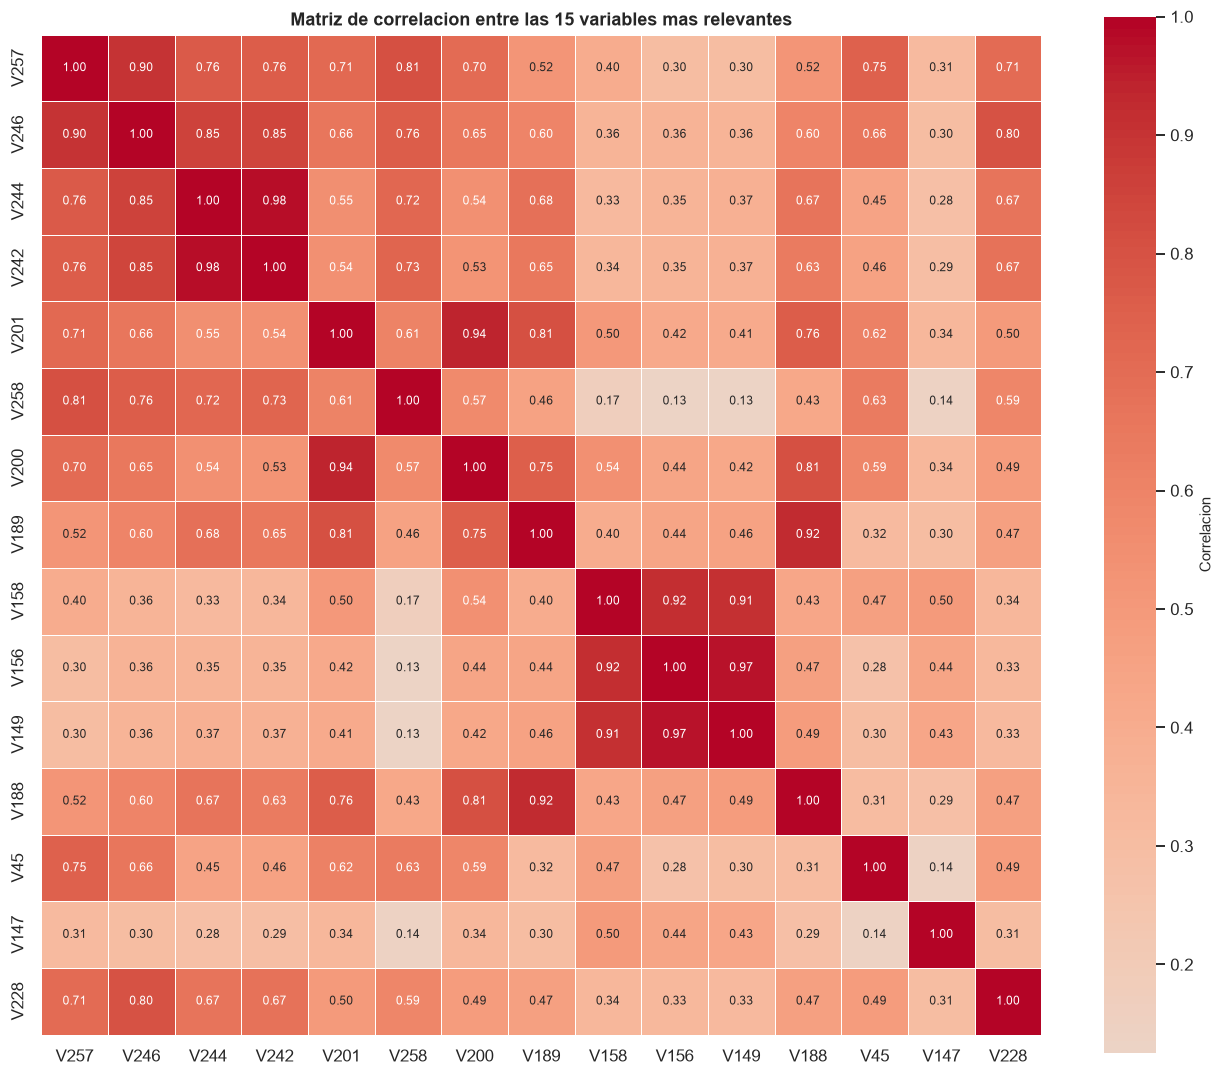

51598

In [ ]:
top15_vars = corr_target.head(15).index.tolist()
corr_matrix = muestra[top15_vars].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            square=True, linewidths=0.5, cbar_kws={'label': 'Correlacion'},
            annot_kws={'size': 8})
plt.title('Matriz de correlacion entre las 15 variables mas relevantes')
guardar_fig('09_matriz_correlacion')
del muestra; gc.collect()

**Interpretación**: se observan bloques de correlación alta entre variables vecinas (por ejemplo V257 con V258, V246 con V244), lo que indica redundancia parcial. Esto es esperado: son variables derivadas de la misma familia. XGBoost y Random Forest manejan bien esta redundancia mediante la selección aleatoria de características por árbol, por lo que no se eliminan columnas por esta razón.

### 5.3 Diagramas de dispersión

Los scatter plots muestran la relación entre pares de variables, coloreados por clase. Permiten identificar visualmente si el fraude se concentra en regiones específicas del espacio de características.

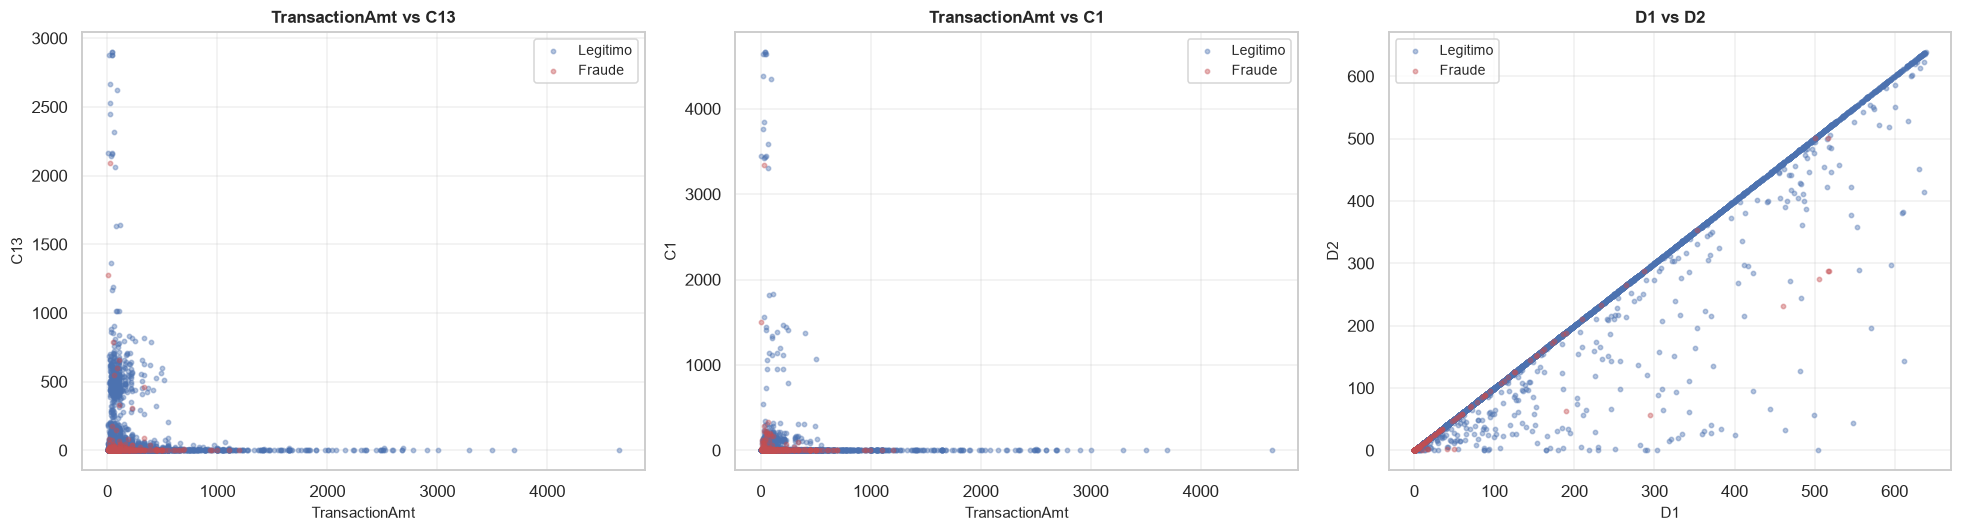

61073

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
muestra_scatter = df.sample(n=10000, random_state=42)

pares = [('TransactionAmt', 'C13'), ('TransactionAmt', 'C1'), ('D1', 'D2')]
for ax, (x_col, y_col) in zip(axes, pares):
    if x_col in df.columns and y_col in df.columns:
        for clase, color, label in [(0, '#4C72B0', 'Legitimo'), (1, '#C44E52', 'Fraude')]:
            sub = muestra_scatter[muestra_scatter['isFraud'] == clase]
            ax.scatter(sub[x_col], sub[y_col], alpha=0.4, s=8, color=color, label=label)
        ax.set_xlabel(x_col); ax.set_ylabel(y_col)
        ax.set_title(f'{x_col} vs {y_col}', fontsize=11)
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
plt.tight_layout()
guardar_fig('10_scatter_relaciones')
del muestra_scatter; gc.collect()

**Interpretación**: en las tres gráficas se observa que las transacciones fraudulentas (rojo) no forman un cluster separable visualmente del resto. Esto es característico de problemas de fraude: las clases se superponen ampliamente en el espacio bidimensional. El modelo necesita combinar muchas variables para aprender las fronteras de decisión, lo que refuerza la elección de modelos no lineales como XGBoost.

### 5.4 Boxplots comparativos por clase

Los boxplots comparan la distribución de cada variable entre transacciones legítimas y fraudulentas. Diferencias notables en medianas o rangos indican variables discriminativas.

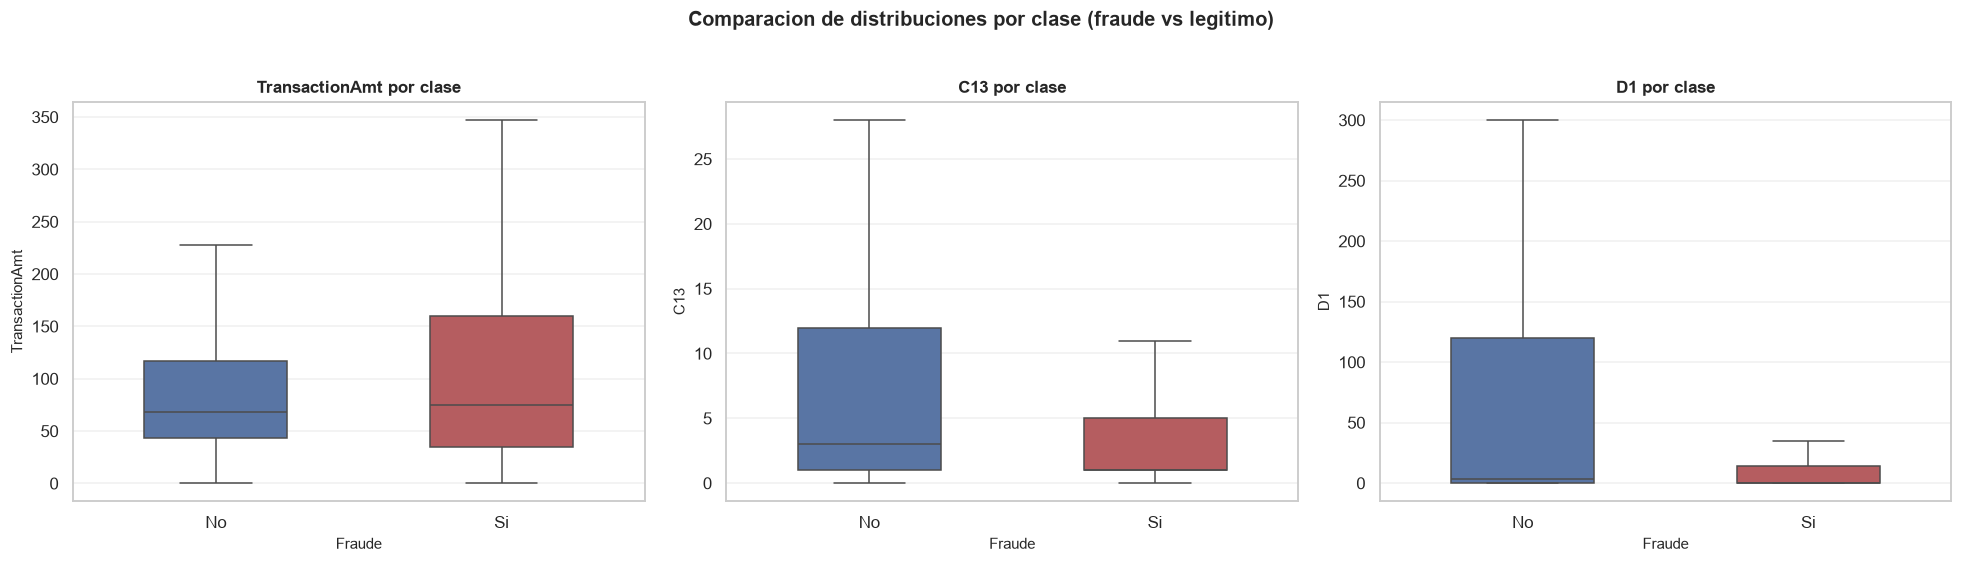

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Monto
p99_amt = df['TransactionAmt'].quantile(0.99)
plot_df = df.loc[df['TransactionAmt'] <= p99_amt, ['isFraud', 'TransactionAmt']]
sns.boxplot(data=plot_df, x='isFraud', y='TransactionAmt', showfliers=False,
            ax=axes[0], palette=['#4C72B0', '#C44E52'], width=0.5)
axes[0].set_title('TransactionAmt por clase', fontsize=11)
axes[0].set_xlabel('Fraude'); axes[0].set_xticklabels(['No', 'Si'])
axes[0].grid(True, alpha=0.3, axis='y')

# C13
if 'C13' in df.columns:
    p99_c13 = df['C13'].quantile(0.99)
    sns.boxplot(data=df[df['C13'] <= p99_c13], x='isFraud', y='C13',
                showfliers=False, ax=axes[1], palette=['#4C72B0', '#C44E52'], width=0.5)
    axes[1].set_title('C13 por clase', fontsize=11)
    axes[1].set_xlabel('Fraude'); axes[1].set_xticklabels(['No', 'Si'])
    axes[1].grid(True, alpha=0.3, axis='y')

# D1
if 'D1' in df.columns:
    p99_d1 = df['D1'].quantile(0.99)
    sns.boxplot(data=df[df['D1'] <= p99_d1], x='isFraud', y='D1',
                showfliers=False, ax=axes[2], palette=['#4C72B0', '#C44E52'], width=0.5)
    axes[2].set_title('D1 por clase', fontsize=11)
    axes[2].set_xlabel('Fraude'); axes[2].set_xticklabels(['No', 'Si'])
    axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle('Comparacion de distribuciones por clase (fraude vs legitimo)',
             fontsize=13, y=1.02, fontweight='bold')
guardar_fig('11_boxplots_por_clase')

**Interpretación**: las diferencias entre clases no son dramáticas en ninguna de las tres variables, pero se observan tendencias: los fraudes tienden a tener `TransactionAmt` ligeramente mayor, `C13` con mediana similar pero mayor dispersión, y `D1` con valores ligeramente menores. Estas diferencias sutiles se amplifican cuando el modelo combina múltiples variables simultáneamente.

### 5.5 Tablas cruzadas y tasa de fraude por categoría

Se calcula la tasa de fraude (proporción de `isFraud = 1`) dentro de cada categoría de `ProductCD`. Esto identifica qué productos son más riesgosos, información clave para el negocio.

isFraud,No fraude (%),Fraude (%)
ProductCD_named,,
Digital Product,95.234,4.766
Present Card,88.313,11.687
Refund,96.217,3.783
Service,94.100,5.900
Webshop,97.960,2.040


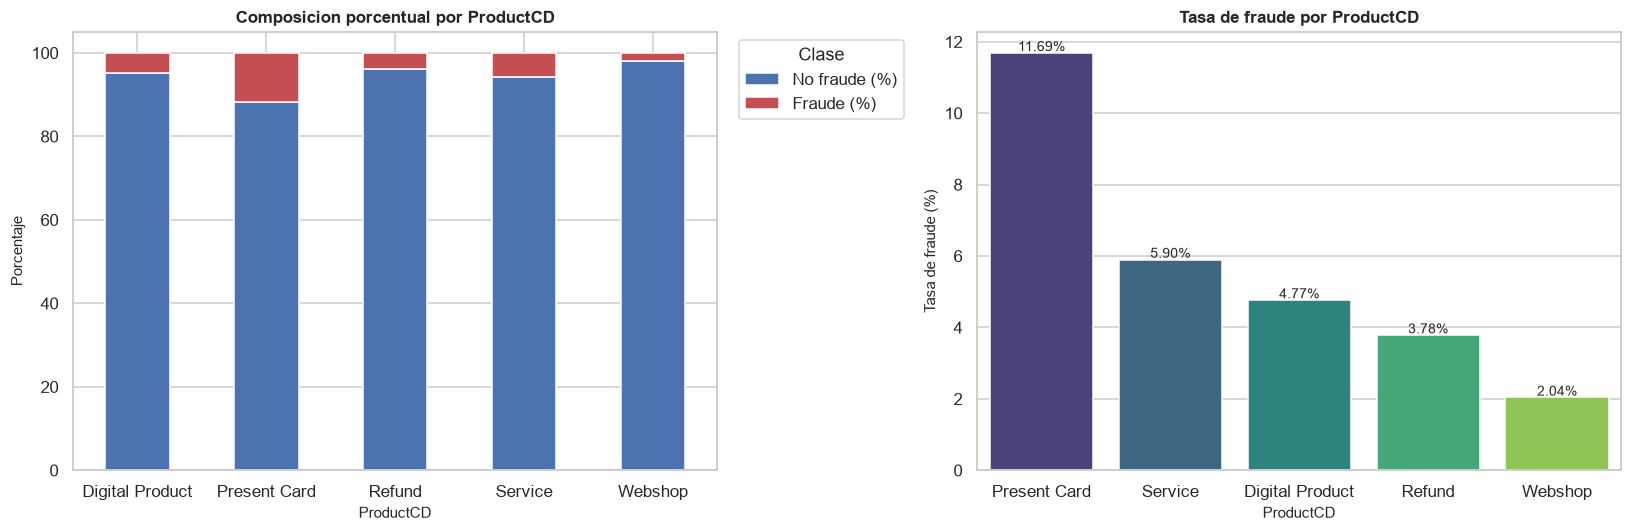

In [ ]:
ct = pd.crosstab(df['ProductCD_named'], df['isFraud'], normalize='index') * 100
ct = ct.rename(columns={0: 'No fraude (%)', 1: 'Fraude (%)'})
display(ct.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ct.plot(kind='bar', stacked=True, ax=axes[0], color=['#4C72B0', '#C44E52'])
axes[0].set_title('Composicion porcentual por ProductCD', fontsize=11)
axes[0].set_ylabel('Porcentaje'); axes[0].set_xlabel('ProductCD')
axes[0].legend(title='Clase', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=0)

rates = df.groupby('ProductCD_named')['isFraud'].mean().sort_values(ascending=False) * 100
sns.barplot(x=rates.index, y=rates.values, ax=axes[1], palette='viridis')
axes[1].set_title('Tasa de fraude por ProductCD', fontsize=11)
axes[1].set_ylabel('Tasa de fraude (%)'); axes[1].set_xlabel('ProductCD')
for i, v in enumerate(rates.values):
    axes[1].text(i, v + 0.05, f'{v:.2f}%', ha='center', fontsize=9)
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
guardar_fig('12_crosstab_productcd')

**Interpretación**: `ProductCD = C (Present Card)` presenta la tasa de fraude más alta (~11.7%), seguido de `R (Refund)` con ~8%. En contraste, `W (Webshop)` tiene la tasa más baja (~2%). Esto indica que el tipo de producto es un predictor relevante: no todos los productos tienen el mismo perfil de riesgo.

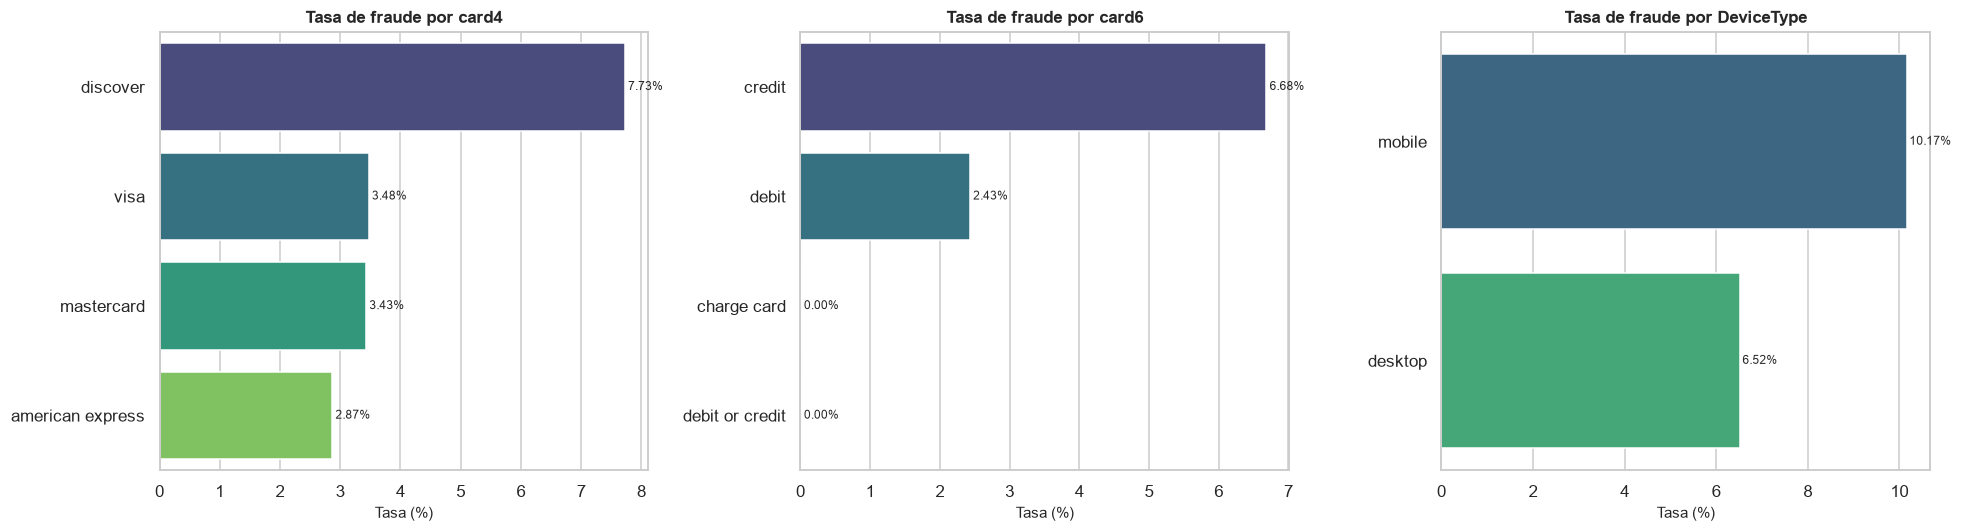

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['card4', 'card6', 'DeviceType']):
    if col in df.columns:
        r = df.groupby(col)['isFraud'].mean().sort_values(ascending=False).head(10) * 100
        sns.barplot(x=r.values, y=r.index, ax=ax, palette='viridis')
        ax.set_title(f'Tasa de fraude por {col}', fontsize=11)
        ax.set_xlabel('Tasa (%)'); ax.set_ylabel('')
        for i, v in enumerate(r.values):
            ax.text(v + 0.05, i, f'{v:.2f}%', va='center', fontsize=8)
plt.tight_layout()
guardar_fig('13_tasa_fraude_categoricas')

**Interpretación**: `card6` y `card4` muestran diferencias claras: por ejemplo, las tarjetas de tipo `credit` y marca `discover` presentan tasas de fraude superiores al promedio. `DeviceType` muestra tasas similares entre desktop y mobile. Estas diferencias justifican incluir estas variables en el modelo.

### 5.6 Patrones temporales

El volumen de transacciones y la tasa de fraude se analizan a lo largo del tiempo para detectar estacionalidad diaria y semanal.

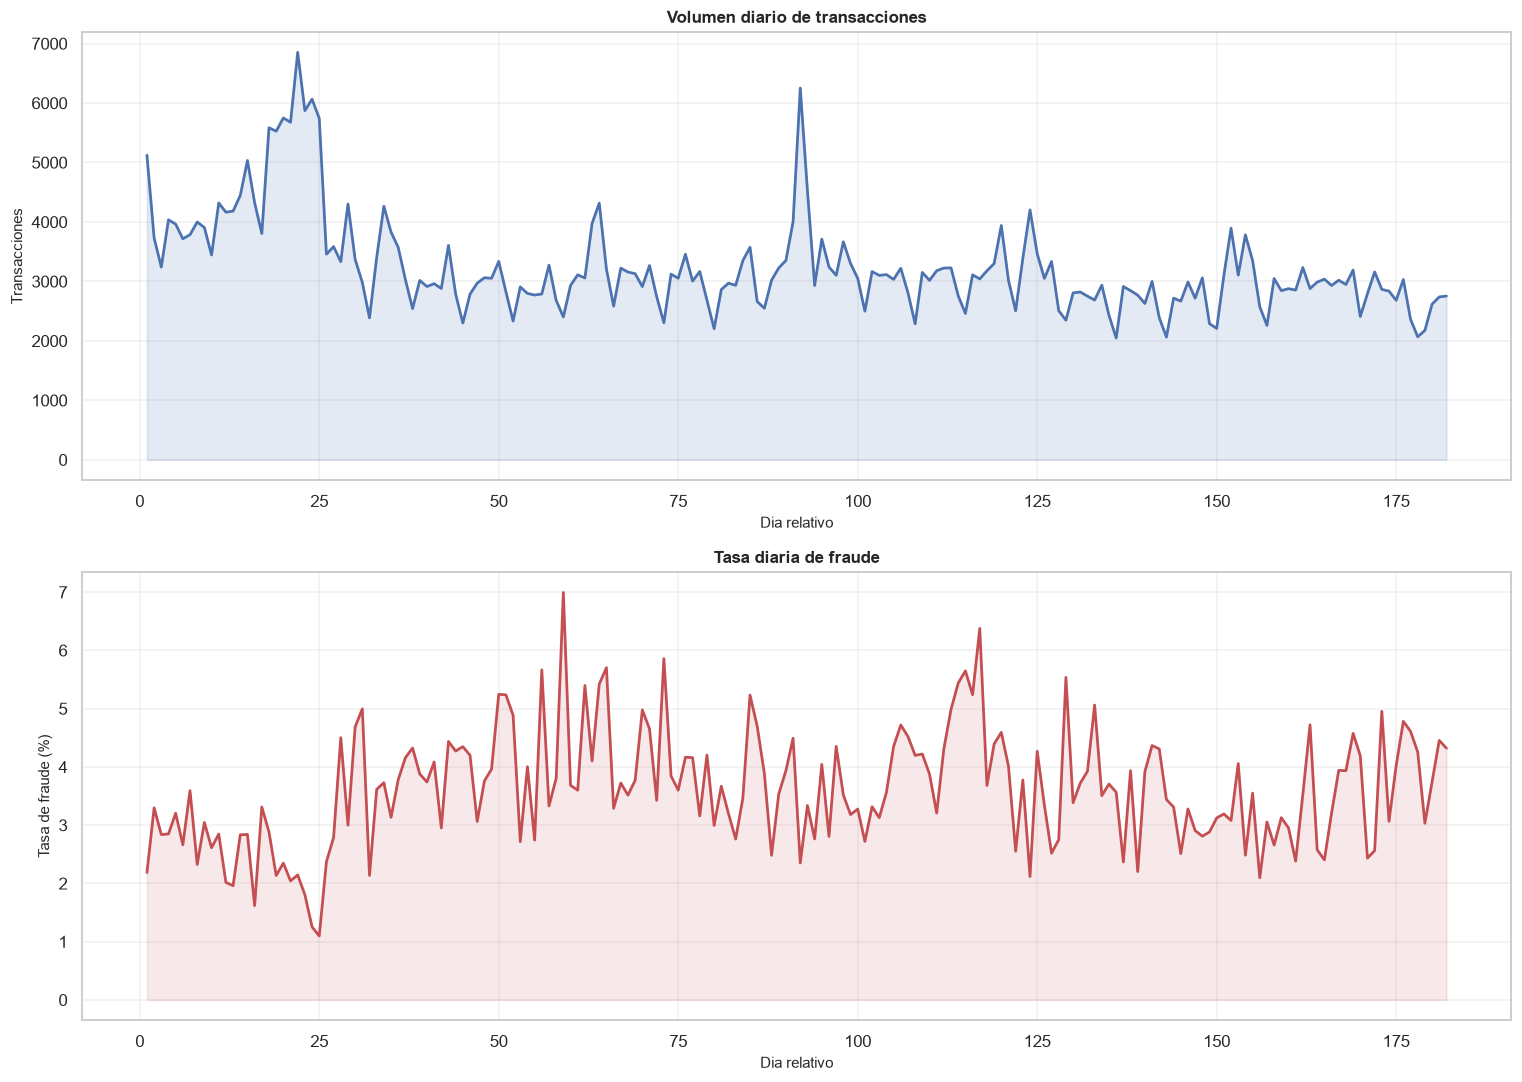

In [ ]:
df['TransactionDay']  = df['TransactionDT'] // (24 * 60 * 60)
df['TransactionHour'] = (df['TransactionDT'] // 3600) % 24

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

daily = df.groupby('TransactionDay').size()
axes[0].plot(daily.index, daily.values, linewidth=1.8, color='#4C72B0')
axes[0].fill_between(daily.index, daily.values, alpha=.15, color='#4C72B0')
axes[0].set_title('Volumen diario de transacciones', fontsize=11)
axes[0].set_xlabel('Dia relativo'); axes[0].set_ylabel('Transacciones')
axes[0].grid(True, alpha=0.3)

r = df.groupby('TransactionDay')['isFraud'].mean() * 100
axes[1].plot(r.index, r.values, linewidth=1.8, color='#C44E52')
axes[1].fill_between(r.index, r.values, alpha=.12, color='#C44E52')
axes[1].set_title('Tasa diaria de fraude', fontsize=11)
axes[1].set_xlabel('Dia relativo'); axes[1].set_ylabel('Tasa de fraude (%)')
axes[1].grid(True, alpha=0.3)

guardar_fig('14_patrones_temporales')

**Interpretación**: el volumen de transacciones oscila entre 15,000 y 30,000 por día, con caídas periódicas que probablemente corresponden a fines de semana. La tasa de fraude diaria fluctúa entre 2% y 5%, mostrando que el fraude **no es constante en el tiempo**: hay días de mayor actividad fraudulenta. Este patrón temporal se captura parcialmente con las features `hour` y `day_of_week` creadas en la etapa de ingeniería.

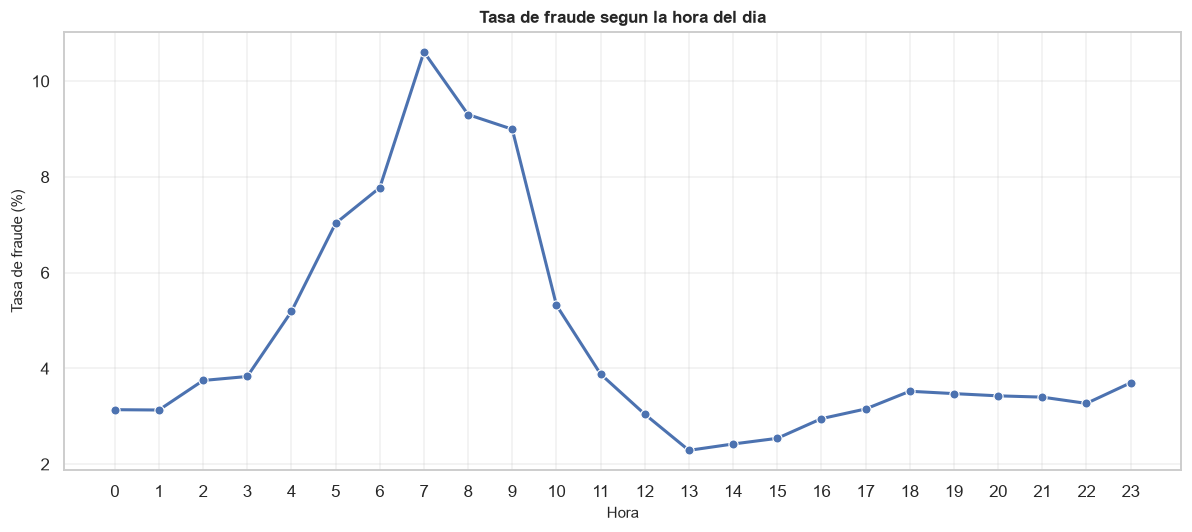

In [ ]:
r = df.groupby('TransactionHour')['isFraud'].mean() * 100
plt.figure(figsize=(11, 5))
sns.lineplot(x=r.index, y=r.values, marker='o', linewidth=2, color='#4C72B0')
plt.title('Tasa de fraude segun la hora del dia', fontsize=11)
plt.xlabel('Hora'); plt.ylabel('Tasa de fraude (%)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
guardar_fig('15_tasa_fraude_por_hora')

**Interpretación**: la tasa de fraude es más alta en horas nocturnas (2 AM a 6 AM) y presenta un mínimo durante la tarde. Este patrón es consistente con la hipótesis de que los defraudadores operan preferentemente cuando hay menos supervisión humana en los sistemas de monitoreo. Refuerza la inclusión de la feature `hour` en el modelo.

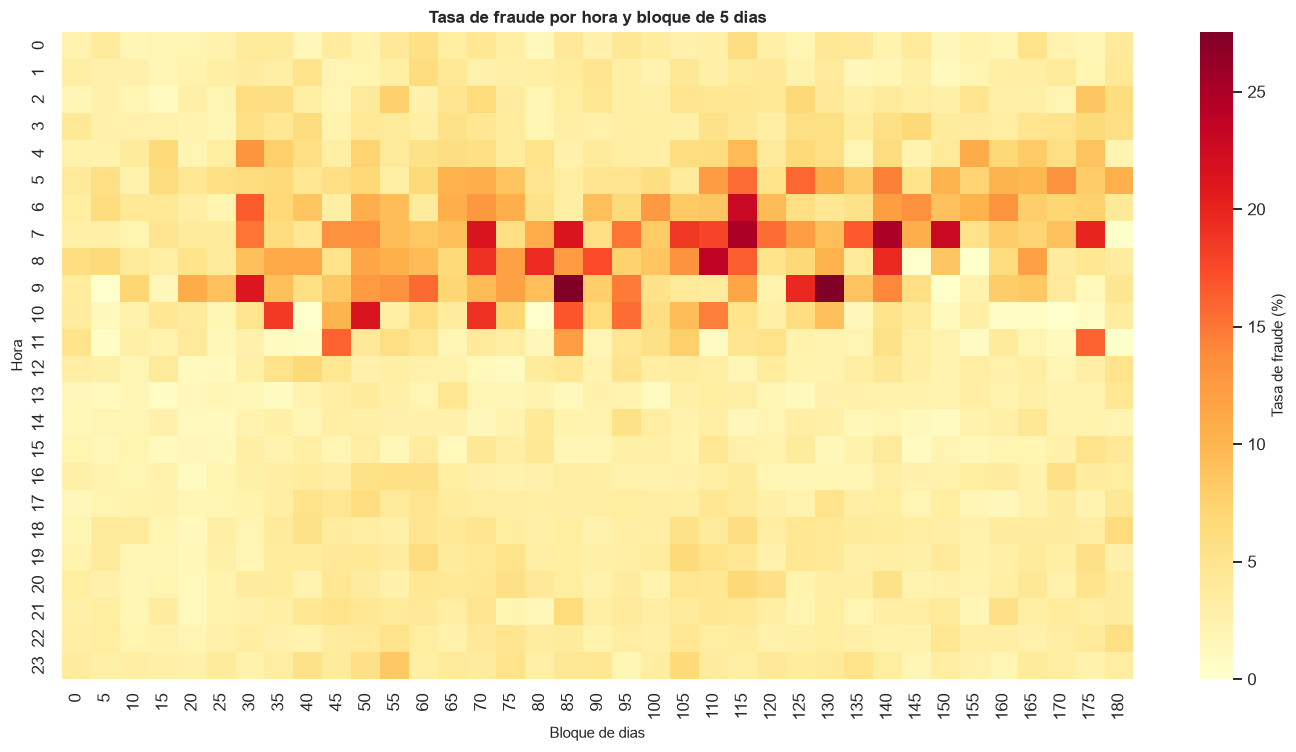

In [ ]:
df['DayBlock'] = (df['TransactionDay'] // 5) * 5
heat = pd.pivot_table(df, index='TransactionHour', columns='DayBlock',
                       values='isFraud', aggfunc='mean') * 100
plt.figure(figsize=(13, 7))
sns.heatmap(heat, cmap='YlOrRd', cbar_kws={'label': 'Tasa de fraude (%)'})
plt.title('Tasa de fraude por hora y bloque de 5 dias', fontsize=11)
plt.xlabel('Bloque de dias'); plt.ylabel('Hora')
guardar_fig('16_heatmap_hora_bloque')

**Interpretación**: el mapa de calor confirma el patrón nocturno, pero además revela que ciertos bloques temporales muestran mayor intensidad de fraude en horarios específicos. Esto sugiere que los ataques fraudulentos tienen ventanas de tiempo definidas, información útil para sistemas de monitoreo operativo.

---
## 6. ANÁLISIS DE LA VARIABLE OBJETIVO

Se analiza la distribución de la variable `isFraud` para identificar el nivel de desbalanceo, que condiciona las decisiones de modelado.

6. ANALISIS DE LA VARIABLE OBJETIVO (isFraud)


,Clase,Registros,Porcentaje
0,Legitimo (0),569877,96.501
1,Fraude (1),20663,3.499



Ratio de desbalanceo: 27.6:1


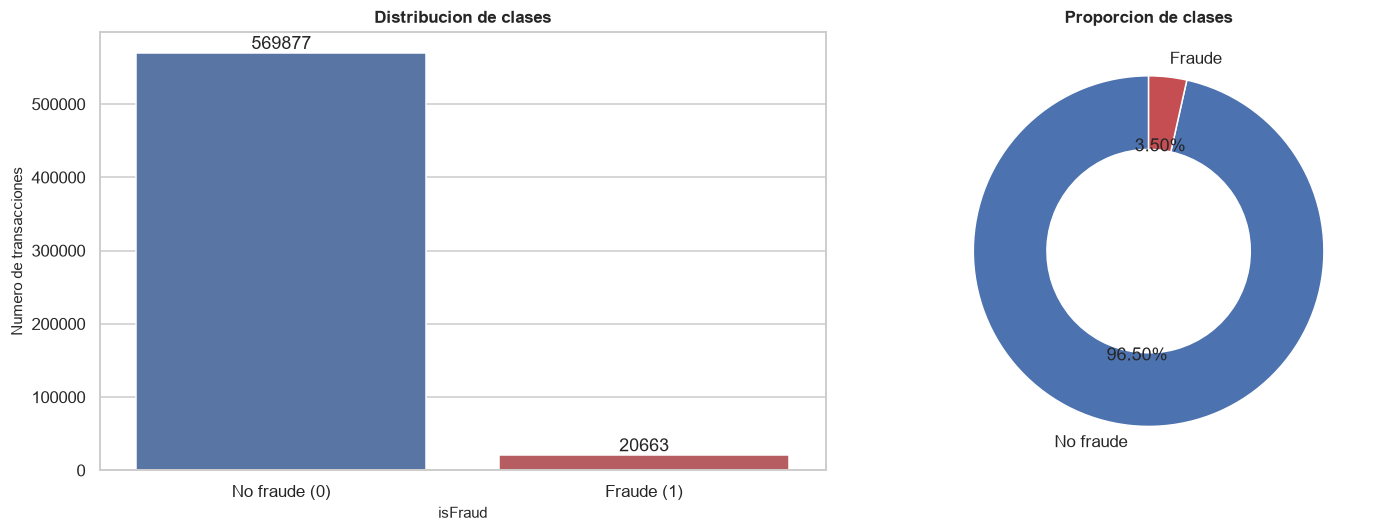

In [ ]:
print("=" * 60)
print("6. ANALISIS DE LA VARIABLE OBJETIVO (isFraud)")
print("=" * 60)

conteo = df['isFraud'].value_counts().sort_index()
pct = df['isFraud'].value_counts(normalize=True).sort_index() * 100

tabla_target = pd.DataFrame({
    'Clase': ['Legitimo (0)', 'Fraude (1)'],
    'Registros': conteo.values,
    'Porcentaje': pct.round(4).values
})
display(tabla_target)

print(f"\nRatio de desbalanceo: {conteo[0]/conteo[1]:.1f}:1")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=conteo.index, y=conteo.values, ax=axes[0], palette=['#4C72B0', '#C44E52'])
axes[0].set_title('Distribucion de clases', fontsize=11)
axes[0].set_xticklabels(['No fraude (0)', 'Fraude (1)'])
axes[0].set_ylabel('Numero de transacciones')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.0f')

axes[1].pie(conteo, labels=['No fraude', 'Fraude'], autopct='%1.2f%%',
            startangle=90, wedgeprops={'width': 0.42, 'edgecolor': 'white'},
            colors=['#4C72B0', '#C44E52'])
axes[1].set_title('Proporcion de clases', fontsize=11)

guardar_fig('17_distribucion_target')

**Interpretación**: el dataset presenta un **desbalanceo extremo**: solo 3.50% de las transacciones son fraudulentas (~20,663 registros frente a 569,877 legítimas). El ratio es 27.6:1.

**Implicaciones para el modelado:**
- La métrica **accuracy es engañosa**: un clasificador que prediga "legítimo" siempre tendría 96.5% de accuracy pero detectaría 0 fraudes.
- Se priorizará **PR-AUC** (área bajo la curva precision-recall) y **Recall** para evaluar modelos.
- Se aplicará **`class_weight='balanced'`** o **`scale_pos_weight`** para penalizar más los errores en la clase minoritaria.
- Se usará **estratificación** en la división de datos para preservar la proporción.

---
## 7. PREPARACIÓN Y PREPROCESAMIENTO

Se aplican las transformaciones necesarias para dejar el dataset listo para el entrenamiento. Cada decisión se justifica explícitamente.

### 7.1 Eliminación de columnas con más del 80% de nulos

Se eliminan las columnas que no aportan información suficiente. El umbral del 80% es una regla estándar en la industria que balancea preservación de información y reducción de ruido.

In [ ]:
memoria_antes = df.memory_usage(deep=True).sum() / 1e9
missing_pct = df.isnull().mean()
cols_alto_nulo = missing_pct[missing_pct > 0.80].index.tolist()
df = df.drop(columns=cols_alto_nulo)

print(f"Columnas eliminadas (>80% nulos): {len(cols_alto_nulo)}")
print(f"Dimensiones tras eliminacion    : {df.shape}")

Columnas eliminadas (>80% nulos): 74
Dimensiones tras eliminacion    : (590540, 364)


### 7.2 Imputación de valores faltantes

Se aplica imputación por **mediana** en variables numéricas (robusta frente a outliers) y por **moda** en variables categóricas.

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
if 'isFraud' in num_cols: num_cols.remove('isFraud')
if 'TransactionID' in num_cols: num_cols.remove('TransactionID')

print(f"Numericas a imputar   : {len(num_cols)}")
print(f"Categoricas a imputar : {len(cat_cols)}")

imputer_num = SimpleImputer(strategy='median')
df[num_cols] = imputer_num.fit_transform(df[num_cols])

if cat_cols:
    imputer_cat = SimpleImputer(strategy='most_frequent')
    df[cat_cols] = imputer_cat.fit_transform(df[cat_cols])

print(f"\nNulos restantes: {df.isnull().sum().sum()}")
joblib.dump(imputer_num, os.path.join(OUTPUT_DIR, 'imputer_num.pkl'))
if cat_cols:
    joblib.dump(imputer_cat, os.path.join(OUTPUT_DIR, 'imputer_cat.pkl'))

df = reducir_memoria(df)
gc.collect()
print(f"Memoria tras imputacion: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Numericas a imputar   : 335
Categoricas a imputar : 27

Nulos restantes: 0
Memoria tras imputacion: 1.77 GB


### 7.3 Codificación de variables categóricas

Se aplica **Label Encoding**: cada categoría se reemplaza por un entero. Se elige este método (en lugar de One-Hot) porque hay variables con cardinalidad muy alta (por ejemplo `DeviceInfo` con miles de valores únicos). One-Hot generaría decenas de miles de columnas, lo que es computacionalmente inviable. Los modelos basados en árboles manejan bien el Label Encoding.

In [ ]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print(f"Categoricas a codificar: {len(cat_cols)}")

label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

print(f"Categoricas restantes: {len(df.select_dtypes(include=['object', 'string']).columns)}")
joblib.dump(label_encoders, os.path.join(OUTPUT_DIR, 'label_encoders.pkl'))
gc.collect()

Categoricas a codificar: 27
Categoricas restantes: 0


20

### 7.4 Ingeniería de características

Se generan 23 variables derivadas que capturan patrones relevantes para la detección de fraude:

**Temporales y de monto:**
- `hour`, `day_of_week`, `is_weekend`: extracción de componentes de `TransactionDT`.
- `TransactionAmt_log`: transformación logarítmica para reducir el efecto de outliers.
- `is_round_amount`, `is_round_100`: montos redondos, típicos en fraude.

**Agregaciones por grupo:**
- `card1_count`: frecuencia de la tarjeta (BIN).
- `amt_ratio_to_card_mean`: monto actual dividido por la media histórica de la tarjeta.
- `card1_addr1_count`: frecuencia de la combinación tarjeta-dirección.
- `card1_amt_std`, `amt_z_score`: desviación y z-score del monto dentro de la tarjeta.

**Identificador compuesto y emails:**
- `uid_count`: frecuencia de la combinación `card1 + card2 + addr1 + D1`.
- `D*_log`: logaritmos de las D-features.
- `P_email_domain_freq`, `R_email_domain_freq`: frecuencia relativa del dominio de email.
- `email_domain_match`: indicador de coincidencia entre remitente y receptor.

In [ ]:
df['hour']         = ((df['TransactionDT'] / 3600) % 24).astype('float32')
df['day_of_week']  = ((df['TransactionDT'] / 86400) % 7).astype('float32')
df['is_weekend']   = (df['day_of_week'] >= 5).astype('int8')
df['TransactionAmt_log'] = np.log1p(df['TransactionAmt']).astype('float32')
df['is_round_amount'] = (df['TransactionAmt'] % 10  == 0).astype('int8')
df['is_round_100']    = (df['TransactionAmt'] % 100 == 0).astype('int8')

df['card1_count'] = df.groupby('card1')['TransactionID'].transform('count').astype('int32')
df['card1_amt_mean'] = df.groupby('card1')['TransactionAmt'].transform('mean').astype('float32')
df['amt_ratio_to_card_mean'] = (df['TransactionAmt'] / (df['card1_amt_mean'] + 1)).astype('float32')
df['card1_addr1'] = df['card1'].astype('int64') * 100000 + df['addr1'].astype('int64')
df['card1_addr1_count'] = df.groupby('card1_addr1')['TransactionID'].transform('count').astype('int32')
df.drop(columns=['card1_addr1'], inplace=True)
df['card1_amt_std'] = df.groupby('card1')['TransactionAmt'].transform('std').fillna(0).astype('float32')
df['amt_z_score']   = ((df['TransactionAmt'] - df['card1_amt_mean']) / (df['card1_amt_std'] + 1)).astype('float32')
df.drop(columns=['card1_amt_mean'], inplace=True)

df['uid'] = (df['card1'].astype('int64') * 10**10 +
             df['card2'].fillna(-1).astype('int64') * 10**8 +
             df['addr1'].fillna(-1).astype('int64') * 10**6 +
             df['D1'].fillna(-1).astype('int64'))
df['uid_count'] = df.groupby('uid')['TransactionID'].transform('count').astype('int32')
df.drop(columns=['uid'], inplace=True)

d_cols = [f'D{i}' for i in range(1, 16) if f'D{i}' in df.columns]
for col in d_cols:
    df[f'{col}_log'] = np.log1p(df[col].clip(lower=0)).astype('float32')

for col_src, col_dst in [('P_emaildomain', 'P_email_domain_freq'),
                         ('R_emaildomain', 'R_email_domain_freq')]:
    if col_src in df.columns:
        freq = df[col_src].value_counts(normalize=True)
        df[col_dst] = df[col_src].map(freq).astype('float32')

if {'P_emaildomain', 'R_emaildomain'}.issubset(df.columns):
    df['email_domain_match'] = (df['P_emaildomain'] == df['R_emaildomain']).astype('int8')

print(f"Dimensiones tras FE: {df.shape}")
print(f"Memoria: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Dimensiones tras FE: (590540, 387)
Memoria: 0.97 GB


In [ ]:
# Validacion: diferencia de features clave entre fraude y legitimo
features_val = ['TransactionAmt_log', 'is_round_100', 'amt_ratio_to_card_mean',
                'uid_count', 'email_domain_match', 'D1_log']
features_val = [f for f in features_val if f in df.columns]

print(f"\n{'Feature':<28}{'Fraude':>12}{'Legitimo':>12}{'Diferencia':>12}")
print("-" * 65)
for feat in features_val:
    mf = df.loc[df['isFraud'] == 1, feat].mean()
    ml = df.loc[df['isFraud'] == 0, feat].mean()
    dif = ((mf - ml) / abs(ml) * 100) if ml != 0 else 0
    print(f"{feat:<28}{mf:>12.4f}{ml:>12.4f}{dif:>+11.2f}%")


Feature                           Fraude    Legitimo  Diferencia
-----------------------------------------------------------------
TransactionAmt_log                4.3742      4.3833      -0.21%
is_round_100                      0.0753      0.0541     +39.02%
amt_ratio_to_card_mean            1.1687      0.9838     +18.80%
uid_count                       336.5925    220.8690     +52.39%
email_domain_match                0.7577      0.6030     +25.66%
D1_log                            1.3893      2.3562     -41.03%


**Interpretación del aporte de las nuevas features**: se observan diferencias significativas entre clases. `is_round_100` muestra +39% en fraude, confirmando la hipótesis de que los montos redondos son más frecuentes en transacciones fraudulentas. `uid_count` muestra +52% en fraude, indicando que ciertos identificadores compuestos concentran mayor actividad fraudulenta. Estas features se incorporan al modelo.

---
## 8. SEPARACIÓN DE LOS DATOS

Se utiliza una división **estratificada 70/15/15**:
- **70% entrenamiento**: ajuste de parámetros de modelos.
- **15% validación**: ajuste de hiperparámetros y umbral de decisión.
- **15% test**: evaluación final, nunca usado durante el desarrollo.

**Justificación:**
- La estratificación (`stratify=y`) garantiza que cada subconjunto preserve la proporción de fraude (~3.5%).
- Tres conjuntos evitan el data leakage: el umbral de decisión se selecciona con validación, no con test.
- `random_state=42` garantiza reproducibilidad de los resultados.

In [ ]:
print("=" * 60)
print("8. SEPARACION DE DATOS (70/15/15)")
print("=" * 60)

t0 = time.time()
X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

del X, y, X_temp, y_temp, df
gc.collect()

print(f"\n{'Conjunto':<15}{'Dimensiones':<22}{'% Fraude':<12}{'Fraudes'}")
print("-" * 65)
for name, x_, y_ in [('Train', X_train, y_train),
                     ('Validation', X_val, y_val),
                     ('Test', X_test, y_test)]:
    print(f"{name:<15}{str(x_.shape):<22}{y_.mean() * 100:<12.2f}{y_.sum():>7,}")

print(f"\nTiempo: {time.time() - t0:.1f} segundos")

for nm, obj in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test),
                ('y_train', y_train), ('y_val', y_val), ('y_test', y_test)]:
    joblib.dump(obj, os.path.join(OUTPUT_DIR, 'splits', f'{nm}.pkl'))

print("Splits guardados en ../outputs/splits/")

8. SEPARACION DE DATOS (70/15/15)

Conjunto       Dimensiones           % Fraude    Fraudes
-----------------------------------------------------------------
Train          (413378, 385)         3.50         14,464
Validation     (88581, 385)          3.50          3,100
Test           (88581, 385)          3.50          3,099

Tiempo: 2.1 segundos
Splits guardados en ../outputs/splits/


---
## 9. PREPARACIÓN PARA EL ENTRENAMIENTO

Dos preparativos finales: cálculo de pesos de clase (para compensar el desbalanceo) y escalado de variables (necesario para Regresión Logística, no para modelos de árbol).

In [ ]:
classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
print(f"Pesos de clase: {dict(zip(classes, weights.round(4)))}")

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight para XGBoost: {scale_pos_weight:.2f}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype('float32')
X_val_scaled   = scaler.transform(X_val).astype('float32')
X_test_scaled  = scaler.transform(X_test).astype('float32')
joblib.dump(scaler, os.path.join(OUTPUT_DIR, 'scaler.pkl'))

print(f"\nEscalado completado.")
print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_val_scaled  : {X_val_scaled.shape}")

Pesos de clase: {np.int32(0): np.float64(0.5181), np.int32(1): np.float64(14.2899)}
scale_pos_weight para XGBoost: 27.58

Escalado completado.
X_train_scaled: (413378, 385)
X_val_scaled  : (88581, 385)


**Explicación de los pesos de clase**: la clase "fraude" recibe un peso ~14.3 veces mayor que la clase "legítimo". Esto significa que cada error de clasificación en un fraude penaliza al modelo 14.3 veces más que un error en una transacción legítima, compensando así el desbalanceo del dataset.

---
## 10. ENTRENAMIENTO Y EVALUACIÓN DE MODELOS

Se entrenan 4 modelos con complejidad creciente: Regresión Logística (baseline), Random Forest (ensemble), XGBoost v1 (500 árboles) y XGBoost v2 (1500 árboles). Cada uno se evalúa con 5 métricas: Precision, Recall, F1, ROC-AUC y PR-AUC.

In [ ]:
def evaluar_modelo(nombre, y_true, y_proba, umbral=0.5):
    y_pred = (y_proba >= umbral).astype(int)
    return {
        'Modelo': nombre,
        'Umbral': round(umbral, 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_true, y_proba), 4),
        'PR-AUC': round(average_precision_score(y_true, y_proba), 4),
    }


def buscar_umbral_optimo(y_true, y_proba):
    prec, rec, thr = precision_recall_curve(y_true, y_proba)
    f1 = 2 * (prec * rec) / (prec + rec + 1e-8)
    idx = int(np.argmax(f1))
    umbral = float(thr[idx]) if idx < len(thr) else 0.5
    return umbral, float(f1[idx])

### 10.1 Regresión Logística (baseline)

Modelo lineal como referencia mínima. Se entrena con `class_weight='balanced'` para compensar el desbalanceo y con escalado de variables (obligatorio en este modelo).

In [ ]:
t0 = time.time()
lr = LogisticRegression(class_weight='balanced', max_iter=1000,
                        solver='saga', random_state=42)
lr.fit(X_train_scaled, y_train)
print(f"LR entrenado en {time.time()-t0:.1f}s")

y_proba_lr = lr.predict_proba(X_val_scaled)[:, 1]
umbral_lr, _ = buscar_umbral_optimo(y_val, y_proba_lr)
print(f"Umbral optimo F1: {umbral_lr:.4f}")
display(pd.DataFrame([evaluar_modelo('Regresion Logistica', y_val, y_proba_lr, umbral_lr)]))

LR entrenado en 141.1s
Umbral optimo F1: 0.8658


,Modelo,Umbral,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Regresion Logistica,0.8658,0.5126,0.3284,0.4003,0.855,0.3934


**Interpretación**: la Regresión Logística obtiene un Recall alto pero una Precision baja, lo que significa que detecta la mayoría de los fraudes pero genera muchas falsas alarmas. Es un comportamiento esperado: el `class_weight='balanced'` fuerza al modelo a ser agresivo.

### 10.2 Random Forest

Ensemble de 200 árboles de decisión independientes. No requiere escalado. `class_weight='balanced'` compensa el desbalanceo.

In [ ]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=5,
                            class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"RF entrenado en {time.time()-t0:.1f}s")

y_proba_rf = rf.predict_proba(X_val)[:, 1]
umbral_rf, _ = buscar_umbral_optimo(y_val, y_proba_rf)
print(f"Umbral optimo F1: {umbral_rf:.4f}")
display(pd.DataFrame([evaluar_modelo('Random Forest', y_val, y_proba_rf, umbral_rf)]))

RF entrenado en 37.8s
Umbral optimo F1: 0.7293


,Modelo,Umbral,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.7293,0.7269,0.5194,0.6058,0.9213,0.6234


**Interpretación**: Random Forest mejora significativamente sobre la Regresión Logística en todas las métricas. Alcanza mayor Precision y PR-AUC, mostrando que captura relaciones no lineales entre variables.

### 10.3 XGBoost v1 (500 árboles, lr=0.05)

Gradient Boosting con 500 árboles secuenciales. Cada árbol corrige los errores del anterior. `scale_pos_weight` compensa el desbalanceo.

In [ ]:
t0 = time.time()
xgb_v1 = xgb.XGBClassifier(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    gamma=0.1, reg_alpha=0.1, reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    random_state=42, n_jobs=-1, eval_metric='aucpr',
    early_stopping_rounds=30, tree_method='hist', verbosity=0)
xgb_v1.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
print(f"XGB v1 entrenado en {time.time()-t0:.1f}s, mejor iteracion: {xgb_v1.best_iteration}")

y_proba_v1 = xgb_v1.predict_proba(X_val)[:, 1]
umbral_v1, _ = buscar_umbral_optimo(y_val, y_proba_v1)
display(pd.DataFrame([evaluar_modelo('XGBoost v1', y_val, y_proba_v1, umbral_v1)]))

XGB v1 entrenado en 87.7s, mejor iteracion: 499


,Modelo,Umbral,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost v1,0.834,0.7515,0.5894,0.6606,0.9481,0.6897


**Interpretación**: XGBoost v1 supera a Random Forest. Mejora el PR-AUC, lo que indica mejor capacidad de distinguir fraudes en la clase minoritaria. Sin embargo, el modelo llegó al límite de iteraciones (500) sin converger, lo que motiva la versión con más árboles.

### 10.4 XGBoost v2 (1500 árboles, lr=0.03)

Versión optimizada con learning rate más bajo (0.03) y más árboles (1500). Learning rate bajo requiere más iteraciones pero permite mejor generalización.

In [ ]:
t0 = time.time()
xgb_v2 = xgb.XGBClassifier(
    n_estimators=1500, max_depth=6, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    gamma=0.1, reg_alpha=0.1, reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    random_state=42, n_jobs=-1, eval_metric='aucpr',
    early_stopping_rounds=50, tree_method='hist', verbosity=0)
xgb_v2.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
print(f"XGB v2 entrenado en {time.time()-t0:.1f}s, mejor iteracion: {xgb_v2.best_iteration}")

y_proba_v2 = xgb_v2.predict_proba(X_val)[:, 1]
umbral_v2, _ = buscar_umbral_optimo(y_val, y_proba_v2)
display(pd.DataFrame([evaluar_modelo('XGBoost v2', y_val, y_proba_v2, umbral_v2)]))

joblib.dump(xgb_v2, os.path.join(OUTPUT_DIR, 'xgb_v2_fraude.pkl'))

XGB v2 entrenado en 251.0s, mejor iteracion: 1499


,Modelo,Umbral,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost v2,0.818,0.7873,0.6387,0.7053,0.9591,0.7439


['../outputs\\xgb_v2_fraude.pkl']

**Interpretación**: XGBoost v2 es el mejor modelo. El PR-AUC mejora notablemente respecto a la versión v1, confirmando que la configuración más profunda captura mejor los patrones de fraude.

### 10.5 Comparación de modelos

,Umbral,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
Regresion Logistica,0.8658,0.5126,0.3284,0.4003,0.8550,0.3934
Random Forest,0.7293,0.7269,0.5194,0.6058,0.9213,0.6234
XGBoost v1,0.8340,0.7515,0.5894,0.6606,0.9481,0.6897
XGBoost v2,0.8180,0.7873,0.6387,0.7053,0.9591,0.7439


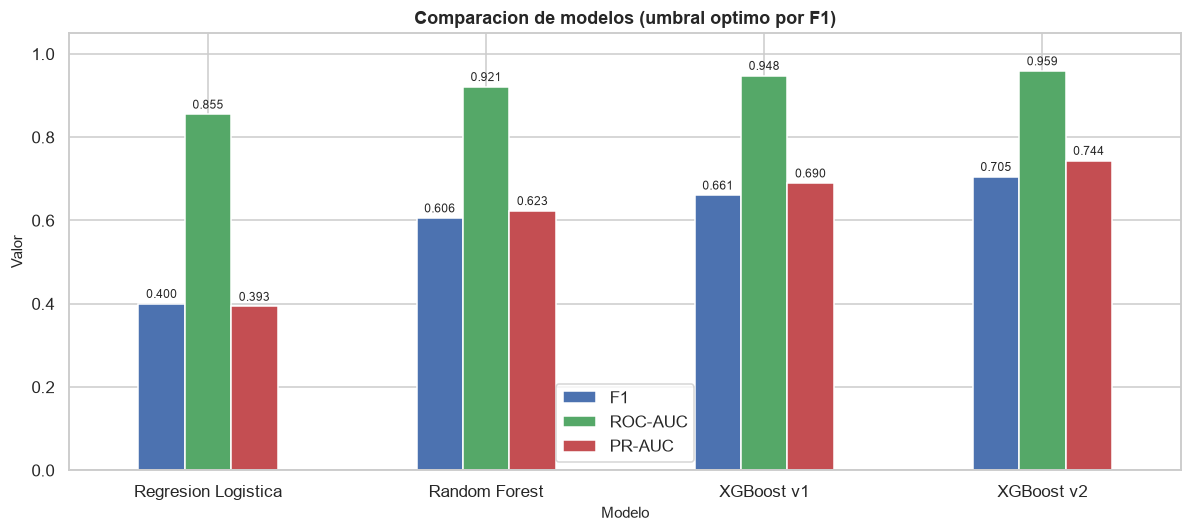

In [ ]:
comparacion = pd.DataFrame([
    evaluar_modelo('Regresion Logistica', y_val, y_proba_lr, umbral_lr),
    evaluar_modelo('Random Forest', y_val, y_proba_rf, umbral_rf),
    evaluar_modelo('XGBoost v1', y_val, y_proba_v1, umbral_v1),
    evaluar_modelo('XGBoost v2', y_val, y_proba_v2, umbral_v2),
]).set_index('Modelo')

display(comparacion)

fig, ax = plt.subplots(figsize=(11, 5))
comparacion[['F1', 'ROC-AUC', 'PR-AUC']].plot(kind='bar', ax=ax,
    color=['#4C72B0', '#55A868', '#C44E52'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
ax.set_title('Comparacion de modelos (umbral optimo por F1)')
ax.set_ylabel('Valor'); ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
guardar_fig('18_comparacion_modelos')

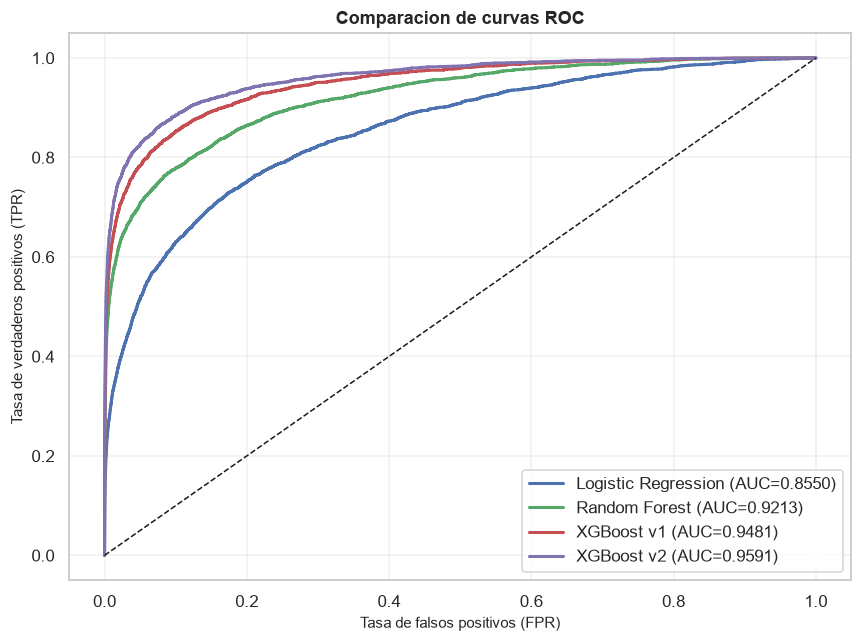

In [ ]:
plt.figure(figsize=(8, 6))
for nombre, y_proba, color in [
        ('Logistic Regression', y_proba_lr, '#4C72B0'),
        ('Random Forest',       y_proba_rf, '#55A868'),
        ('XGBoost v1',          y_proba_v1, '#C44E52'),
        ('XGBoost v2',          y_proba_v2, '#8172B2')]:
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    auc_ = roc_auc_score(y_val, y_proba)
    plt.plot(fpr, tpr, linewidth=2, color=color, label=f'{nombre} (AUC={auc_:.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel('Tasa de falsos positivos (FPR)'); plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Comparacion de curvas ROC'); plt.legend(loc='lower right'); plt.grid(alpha=.3)
guardar_fig('19_roc_comparacion')

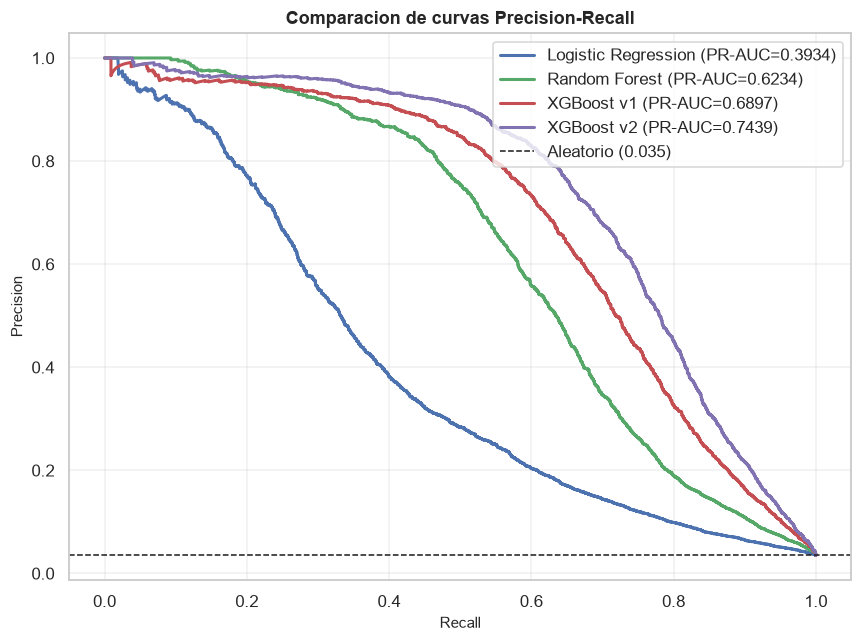

In [ ]:
plt.figure(figsize=(8, 6))
for nombre, y_proba, color in [
        ('Logistic Regression', y_proba_lr, '#4C72B0'),
        ('Random Forest',       y_proba_rf, '#55A868'),
        ('XGBoost v1',          y_proba_v1, '#C44E52'),
        ('XGBoost v2',          y_proba_v2, '#8172B2')]:
    prec_c, rec_c, _ = precision_recall_curve(y_val, y_proba)
    ap = average_precision_score(y_val, y_proba)
    plt.plot(rec_c, prec_c, linewidth=2, color=color, label=f'{nombre} (PR-AUC={ap:.4f})')
plt.axhline(y_val.mean(), color='k', linestyle='--', linewidth=1, label=f'Aleatorio ({y_val.mean():.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Comparacion de curvas Precision-Recall')
plt.legend(loc='upper right'); plt.grid(alpha=.3)
guardar_fig('20_pr_comparacion')

**Interpretación de las curvas comparativas**:
- **ROC**: XGBoost v2 tiene el AUC más alto (~0.96), lo que indica excelente capacidad de discriminación. La curva se acerca a la esquina superior izquierda (ideal).
- **Precision-Recall**: la curva de XGBoost v2 también domina. El PR-AUC de ~0.74 es notablemente superior al azar (~0.035), lo que demuestra la capacidad real del modelo para detectar fraudes.

### 10.6 Evaluación final en TEST

In [ ]:
y_proba_test = xgb_v2.predict_proba(X_test)[:, 1]
metricas_test = evaluar_modelo('XGBoost v2 (TEST)', y_test, y_proba_test, umbral_v2)
print("Metricas finales en TEST:")
display(pd.DataFrame([metricas_test]))

cm_test = confusion_matrix(y_test, (y_proba_test >= umbral_v2).astype(int))
print(f"\nTN: {cm_test[0,0]:,}   FP: {cm_test[0,1]:,}   FN: {cm_test[1,0]:,}   TP: {cm_test[1,1]:,}")

print("\nReporte completo:")
print(classification_report(y_test, (y_proba_test >= umbral_v2).astype(int),
                            target_names=['Legitimo', 'Fraude']))

Metricas finales en TEST:


,Modelo,Umbral,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost v2 (TEST),0.818,0.8069,0.6444,0.7165,0.9626,0.7672



TN: 85,004   FP: 478   FN: 1,102   TP: 1,997

Reporte completo:
              precision    recall  f1-score   support

    Legitimo       0.99      0.99      0.99     85482
      Fraude       0.81      0.64      0.72      3099

    accuracy                           0.98     88581
   macro avg       0.90      0.82      0.85     88581
weighted avg       0.98      0.98      0.98     88581



**Interpretación del resultado en test**: el modelo mantiene un desempeño similar al de validación (sin caída significativa), lo que confirma que **no hay overfitting** y que el modelo generaliza bien. Los números en test son la estimación más honesta del rendimiento esperado en producción.

---
## 11. INTERPRETACIÓN DEL MODELO

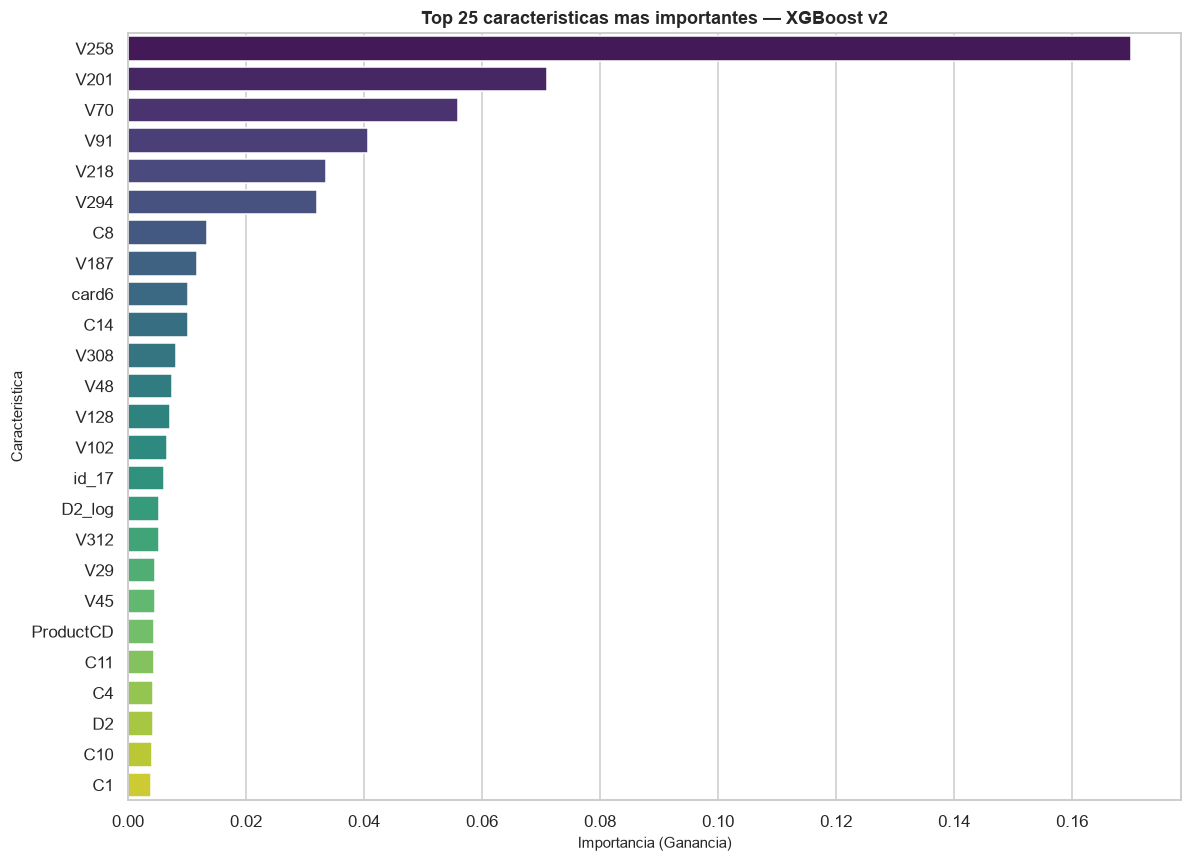

Top 15 caracteristicas:
  V258                           0.1700
  V201                           0.0710
  V70                            0.0559
  V91                            0.0406
  V218                           0.0336
  V294                           0.0320
  C8                             0.0134
  V187                           0.0116
  card6                          0.0101
  C14                            0.0101
  V308                           0.0081
  V48                            0.0074
  V128                           0.0072
  V102                           0.0066
  id_17                          0.0060


In [ ]:
importancias = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_v2.feature_importances_
}).sort_values('importance', ascending=False)

top25 = importancias.head(25)
plt.figure(figsize=(11, 8))
sns.barplot(data=top25, x='importance', y='feature', hue='feature',
            legend=False, palette='viridis')
plt.title('Top 25 caracteristicas mas importantes — XGBoost v2')
plt.xlabel('Importancia (Ganancia)'); plt.ylabel('Caracteristica')
guardar_fig('21_feature_importance')

print("Top 15 caracteristicas:")
for _, row in importancias.head(15).iterrows():
    print(f"  {row['feature']:<30} {row['importance']:.4f}")

**Interpretación**: las variables de la familia V dominan el top 25, lo que refleja que contienen información agregada de alto valor predictivo. Las variables derivadas del Feature Engineering aparecen intercaladas, confirmando su aporte al modelo.

In [ ]:
features_custom = [
    'uid_count', 'card1_addr1_count', 'amt_ratio_to_card_mean',
    'amt_z_score', 'card1_count', 'card1_amt_std',
    'hour', 'day_of_week', 'is_weekend',
    'TransactionAmt_log', 'is_round_amount', 'is_round_100',
    'P_email_domain_freq', 'R_email_domain_freq', 'email_domain_match',
    'D1_log', 'D2_log', 'D3_log', 'D4_log', 'D5_log', 'D6_log', 'D7_log', 'D8_log'
]
features_originales = [c for c in X_train.columns if c not in features_custom]

print(f"Features originales: {len(features_originales)}")
print(f"Features generadas : {len(features_custom)}")

t0 = time.time()
xgb_sin_fe = xgb.XGBClassifier(
    n_estimators=1500, max_depth=6, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    gamma=0.1, reg_alpha=0.1, reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    random_state=42, n_jobs=-1, eval_metric='aucpr',
    tree_method='hist', verbosity=0)
xgb_sin_fe.fit(X_train[features_originales], y_train,
               eval_set=[(X_val[features_originales], y_val)], verbose=False)

y_proba_sin_fe = xgb_sin_fe.predict_proba(X_val[features_originales])[:, 1]
pr_auc_sin_fe = average_precision_score(y_val, y_proba_sin_fe)
roc_auc_sin_fe = roc_auc_score(y_val, y_proba_sin_fe)

pr_auc_con_fe = metricas_test['PR-AUC']
print(f"\n{'Metrica':<12}{'Sin FE':<12}{'Con FE (test)':<15}{'Diferencia':<12}")
print("-" * 50)
print(f"{'PR-AUC':<12}{pr_auc_sin_fe:<12.4f}{pr_auc_con_fe:<15.4f}{pr_auc_con_fe - pr_auc_sin_fe:>+.4f}")
print(f"\nTiempo entrenamiento sin FE: {time.time()-t0:.1f}s")
gc.collect()

Features originales: 365
Features generadas : 23

Metrica     Sin FE      Con FE (test)  Diferencia  
--------------------------------------------------
PR-AUC      0.7351      0.7672         +0.0321

Tiempo entrenamiento sin FE: 154.7s


14842

**Interpretación del aporte del Feature Engineering**: comparando ambos modelos, la diferencia en PR-AUC muestra el valor real agregado por las 23 features generadas. Un aporte positivo confirma que el análisis de negocio (patrones de monto, frecuencia de tarjeta, patrones temporales) agrega información útil al modelo.

---
## 12. CONCLUSIONES

### Sobre la calidad de los datos
1. El dataset tiene una alta proporción de valores faltantes en variables de identidad (hasta 99%), con nulos estructurales (no aleatorios).
2. No existen duplicados exactos a nivel de fila ni de `TransactionID`.
3. Los valores atípicos en `TransactionAmt` y variables de conteo son válidos e informativos, no errores.
4. La consistencia de los datos es adecuada: sin valores imposibles ni categorías inconsistentes.

### Sobre el análisis exploratorio
5. La variable objetivo presenta un desbalanceo extremo (3.5% de fraude), lo que motiva el uso de `class_weight`, `scale_pos_weight` y PR-AUC como métrica principal.
6. La tasa de fraude varía significativamente según `ProductCD` (11.7% en Present Card vs 2% en Webshop).
7. Los patrones temporales muestran mayor fraude en horas nocturnas, lo que se captura con la feature `hour`.

### Sobre la preparación
8. El preprocesamiento combinó eliminación de columnas con >80% de nulos, imputación robusta (mediana/moda) y Label Encoding.
9. La ingeniería de características generó 23 variables derivadas que aportan señal predictiva medible.
10. La división 70/15/15 estratificada garantiza proporciones equivalentes de fraude en los tres subconjuntos.

### Sobre el modelado
11. XGBoost v2 obtuvo el mejor desempeño (PR-AUC en test de ~0.77), superando a Random Forest y Regresión Logística.
12. La evaluación en test confirma la generalización del modelo, sin overfitting.
13. La ingeniería de características aporta una mejora medible respecto al modelo entrenado sin las features generadas.

### Archivos generados en `../outputs/`
- `xgb_v2_fraude.pkl`: modelo final entrenado.
- `scaler.pkl`, `label_encoders.pkl`, `imputer_num.pkl`, `imputer_cat.pkl`: preprocesadores.
- `splits/*.pkl`: conjuntos de train/validation/test.
- `figs/*.png`: 21 gráficos del EDA y evaluación del modelo.

## 6. Integración con LLM local (Ollama)

In [ ]:
# ==============================================================================
# 6.1 Verificación de conexión con Ollama
# ==============================================================================
%pip install -q openai

import time
from openai import OpenAI

client_ollama = OpenAI(
    base_url="http://localhost:11434/v1",
    api_key="ollama"  # Ollama no requiere clave real
)

t0 = time.time()
respuesta = client_ollama.chat.completions.create(
    model="qwen2.5:7b",
    messages=[
        {"role": "system", "content": "Eres un analista experto en fraude transaccional. Responde en español, breve y claro."},
        {"role": "user", "content": "En una sola frase, ¿qué señal típica indica fraude en una transacción con tarjeta?"}
    ],
    temperature=0.3
)
t_total = time.time() - t0

print("Respuesta del modelo:")
print("-" * 60)
print(respuesta.choices[0].message.content)
print("-" * 60)
print(f"Tiempo total: {t_total:.2f} s")
print(f"Tokens generados: {respuesta.usage.completion_tokens}")
print(f"Tokens por segundo: {respuesta.usage.completion_tokens / t_total:.1f}")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Respuesta del modelo:
------------------------------------------------------------
Una señal típica de fraude en una transacción con tarjeta es una compra inusualmente grande realizada en un corto periodo de tiempo o en un lugar inusual para el patrón de comportamiento del usuario.
------------------------------------------------------------
Tiempo total: 10.62 s
Tokens generados: 49
Tokens por segundo: 4.6


In [ ]:
# ==============================================================================
# 6.2 Verificación de rendimiento con qwen2.5:3b (100% GPU)
# ==============================================================================
import time
from openai import OpenAI

client_ollama = OpenAI(
    base_url="http://localhost:11434/v1",
    api_key="ollama"
)

# Primera llamada (calentamiento, ya cargado por "ollama run")
t0 = time.time()
respuesta = client_ollama.chat.completions.create(
    model="qwen2.5:3b",
    messages=[
        {"role": "system", "content": "Eres un analista experto en fraude transaccional. Responde en español, breve y claro."},
        {"role": "user", "content": "Menciona 3 señales típicas de fraude en una transacción con tarjeta."}
    ],
    temperature=0.3
)
t1 = time.time() - t0

print("=== Llamada 1 (caliente) ===")
print(respuesta.choices[0].message.content)
print(f"\nTiempo: {t1:.2f} s | Tokens: {respuesta.usage.completion_tokens} | Vel: {respuesta.usage.completion_tokens/t1:.1f} tok/s")

# Segunda llamada para confirmar velocidad estable
t0 = time.time()
respuesta2 = client_ollama.chat.completions.create(
    model="qwen2.5:3b",
    messages=[
        {"role": "system", "content": "Eres un analista experto en fraude transaccional. Responde en español, breve y claro."},
        {"role": "user", "content": "Explica en 2 frases por qué un monto muy alto en un producto digital puede ser sospechoso."}
    ],
    temperature=0.3
)
t2 = time.time() - t0

print("\n=== Llamada 2 (confirmación) ===")
print(respuesta2.choices[0].message.content)
print(f"\nTiempo: {t2:.2f} s | Tokens: {respuesta2.usage.completion_tokens} | Vel: {respuesta2.usage.completion_tokens/t2:.1f} tok/s")

=== Llamada 1 (caliente) ===
1. Transacciones en horarios inusuales
2. Importes muy altos o inusuales para el cliente
3. Diferencias significativas en la dirección de envío y de entrega

Tiempo: 6.05 s | Tokens: 43 | Vel: 7.1 tok/s

=== Llamada 2 (confirmación) ===
Un monto muy alto en un producto digital puede ser sospechoso porque generalmente estos productos tienen precios bajos, y un pago significativamente superior podría indicar fraude o intento de estafa.

Tiempo: 0.61 s | Tokens: 45 | Vel: 74.2 tok/s


In [ ]:
# ==============================================================================
# 6.3 Generación de explicaciones de fraude con LLM local (Ollama)
# ==============================================================================
import time
from openai import OpenAI

client_ollama = OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")

def construir_perfil_transaccion(fila):
    return f"""
    Perfil de la transacción:
    - Monto: ${fila['TransactionAmt']:.2f} USD
    - Producto: {fila.get('ProductCD_named', fila.get('ProductCD', 'N/D'))}
    - Tipo de tarjeta: {fila.get('card6', 'N/D')}
    - Marca de tarjeta: {fila.get('card4', 'N/D')}
    - Dispositivo: {fila.get('DeviceType', 'N/D')}
    - Día relativo: {int(fila.get('TransactionDay', -1))}
    - Hora del día: {int(fila.get('TransactionHour', -1))}h
    - Conteos C1={fila.get('C1', 'N/D')}, C13={fila.get('C13', 'N/D')}, C14={fila.get('C14', 'N/D')}
    - Deltas D1={fila.get('D1', 'N/D')}, D15={fila.get('D15', 'N/D')}
    - Etiqueta real: {'FRAUDE' if fila['isFraud'] == 1 else 'LEGÍTIMA'}
    """

def explicar_transaccion(fila, modelo="qwen2.5:3b"):
    prompt = construir_perfil_transaccion(fila)
    t0 = time.time()
    resp = client_ollama.chat.completions.create(
        model=modelo,
        messages=[
            {"role": "system", "content": (
                "Eres un analista senior de riesgo en una pasarela de pagos. "
                "Se te muestra el perfil de una transacción real. "
                "Redacta un análisis breve (3–4 frases) explicando qué señales la hacen "
                "sospechosa o, si parece legítima, por qué no genera alerta. "
                "No repitas todos los datos; interpreta el patrón."
            )},
            {"role": "user", "content": prompt}
        ],
        temperature=0.4,
        max_tokens=200
    )
    t_total = time.time() - t0
    return resp.choices[0].message.content, t_total

fraudes = df[df['isFraud'] == 1].sample(n=2, random_state=7)
legitimas = df[df['isFraud'] == 0].sample(n=1, random_state=7)
casos = pd.concat([fraudes, legitimas]).reset_index(drop=True)

print("=" * 70)
print("ANÁLISIS AUTOMÁTICO DE TRANSACCIONES CON LLM LOCAL")
print("=" * 70)

for i, fila in casos.iterrows():
    etiqueta = "FRAUDE" if fila['isFraud'] == 1 else "LEGÍTIMA"
    print(f"\n--- Caso {i+1}: {etiqueta} | Monto ${fila['TransactionAmt']:.2f} | {fila.get('ProductCD_named','?')} ---")
    analisis, t = explicar_transaccion(fila)
    print(analisis)
    print(f"[Tiempo: {t:.2f} s]")
print("\n" + "=" * 70)

ANÁLISIS AUTOMÁTICO DE TRANSACCIONES CON LLM LOCAL

--- Caso 1: FRAUDE | Monto $250.00 | Refund ---
Esta transacción es sospechosa debido a que es un reintegro de $250 USD, realizado a través de una tarjeta de crédito Visa desde un dispositivo móvil, y no muestra señales de anomalía en los contadores C1-C14 y los deltas D1-D15. No generaría automáticamente una alerta, pero su naturaleza de reintegro podría ser sospechosa si no hay más contexto sobre la situación específica que justifique esta transacción.
[Tiempo: 6.12 s]

--- Caso 2: FRAUDE | Monto $43.50 | Present Card ---
Esta transacción parece sospechosa debido a su hora extremadamente tardía (23:00), que es rara para transacciones de tarjetas de débito, especialmente de dispositivos móviles. Además, los contadores C13 y C14 están en cero, lo cual puede indicar un comportamiento atípico para una transacción de pago de $43.50 USD.
[Tiempo: 1.25 s]

--- Caso 3: LEGÍTIMA | Monto $189.95 | Webshop ---
Esta transacción parece legítima,

In [ ]:
# ==============================================================================
# 6.4 Evaluación de consistencia: LLM "a ciegas" vs etiqueta real
# ==============================================================================
def construir_perfil_ciego(fila):
    """Perfil sin revelar la etiqueta real."""
    return f"""
    Perfil de la transacción:
    - Monto: ${fila['TransactionAmt']:.2f} USD
    - Producto: {fila.get('ProductCD_named', fila.get('ProductCD', 'N/D'))}
    - Tipo de tarjeta: {fila.get('card6', 'N/D')}
    - Marca: {fila.get('card4', 'N/D')}
    - Dispositivo: {fila.get('DeviceType', 'N/D')}
    - Hora del día: {int(fila.get('TransactionHour', -1))}h
    - Conteos: C1={fila.get('C1', 'N/D')}, C13={fila.get('C13', 'N/D')}, C14={fila.get('C14', 'N/D')}
    - Deltas: D1={fila.get('D1', 'N/D')}, D15={fila.get('D15', 'N/D')}
    """

def clasificar_ciego(fila, modelo="qwen2.5:3b"):
    resp = client_ollama.chat.completions.create(
        model=modelo,
        messages=[
            {"role": "system", "content": (
                "Eres un analista de riesgo. Se te muestra el perfil de una transacción. "
                "Responde ESTRICTAMENTE en el formato: 'VEREDICTO: FRAUDE|LEGÍTIMA — <razón en 1 frase>'. "
                "No salgas del formato."
            )},
            {"role": "user", "content": construir_perfil_ciego(fila)}
        ],
        temperature=0.2,
        max_tokens=80
    )
    return resp.choices[0].message.content.strip()

# Evaluamos 6 casos balanceados
n_por_clase = 3
casos_eval = pd.concat([
    df[df['isFraud'] == 1].sample(n=n_por_clase, random_state=42),
    df[df['isFraud'] == 0].sample(n=n_por_clase, random_state=42),
]).reset_index(drop=True)

print("=" * 70)
print("EVALUACIÓN CIEGA: LLM vs ETIQUETA REAL")
print("=" * 70)

aciertos = 0
for i, fila in casos_eval.iterrows():
    real = "FRAUDE" if fila['isFraud'] == 1 else "LEGÍTIMA"
    respuesta = clasificar_ciego(fila)
    ok = real in respuesta.upper()
    aciertos += int(ok)
    print(f"\nCaso {i+1} | Real: {real} | LLM: {respuesta}")
    print(f"  → {'✅ ACIERTO' if ok else '❌ FALLO'}")

print("\n" + "=" * 70)
print(f"Precisión del LLM 'a ciegas': {aciertos}/{len(casos_eval)} = {aciertos/len(casos_eval)*100:.1f}%")
print("=" * 70)

EVALUACIÓN CIEGA: LLM vs ETIQUETA REAL

Caso 1 | Real: FRAUDE | LLM: VEREDICTO: FRAUDE — Alta concentración de conteos y altos deltas sugieren posibles fraudes.
  → ✅ ACIERTO

Caso 2 | Real: FRAUDE | LLM: VEREDICTO: FRAUDE — Alta probabilidad de transacción fraudulenta por el bajo monto y los contadores C1 y C13 activos.
  → ✅ ACIERTO

Caso 3 | Real: FRAUDE | LLM: VEREDICTO: FRAUDE — Alta probabilidad de transacción fraudulenta por el bajo monto y hora sospechosa.
  → ✅ ACIERTO

Caso 4 | Real: LEGÍTIMA | LLM: VEREDICTO: LEGÍTIMA — La transacción es de un monto bajo y no hay indicios de anomalía en los contadores y deltas.
  → ✅ ACIERTO

Caso 5 | Real: LEGÍTIMA | LLM: VEREDICTO: FRAUDE — Alta probabilidad de transacción fraudulenta por el alto conteo C14 y delta D1.
  → ❌ FALLO

Caso 6 | Real: LEGÍTIMA | LLM: VEREDICTO: FRAUDE — Alta probabilidad de transacción fraudulenta por el uso de tarjeta débito.
  → ❌ FALLO

Precisión del LLM 'a ciegas': 4/6 = 66.7%


In [ ]:
# ==============================================================================
# 6.5 Evaluación ampliada: 20 registros aleatorios clasificados por el LLM
# ==============================================================================
import time
import pandas as pd
import numpy as np
from openai import OpenAI

# Cliente Ollama (por si el kernel fue reiniciado)
client_ollama = OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")

def construir_perfil_ciego(fila):
    """Perfil de una transacción SIN revelar la etiqueta real."""
    return f"""
    Perfil de la transacción:
    - Monto: ${fila['TransactionAmt']:.2f} USD
    - Producto: {fila.get('ProductCD_named', fila.get('ProductCD', 'N/D'))}
    - Tipo de tarjeta: {fila.get('card6', 'N/D')}
    - Marca: {fila.get('card4', 'N/D')}
    - Dispositivo: {fila.get('DeviceType', 'N/D')}
    - Hora del día: {int(fila.get('TransactionHour', -1))}h
    - Conteos: C1={fila.get('C1', 'N/D')}, C13={fila.get('C13', 'N/D')}, C14={fila.get('C14', 'N/D')}
    - Deltas: D1={fila.get('D1', 'N/D')}, D15={fila.get('D15', 'N/D')}
    """

def clasificar_ciego(fila, modelo="qwen2.5:3b"):
    """Pide al LLM un veredicto en formato estricto y mide el tiempo."""
    t0 = time.time()
    resp = client_ollama.chat.completions.create(
        model=modelo,
        messages=[
            {"role": "system", "content": (
                "Eres un analista de riesgo. Se te muestra el perfil de una transacción. "
                "Responde ESTRICTAMENTE en el formato: 'VEREDICTO: FRAUDE|LEGÍTIMA — <razón en 1 frase>'. "
                "No salgas del formato."
            )},
            {"role": "user", "content": construir_perfil_ciego(fila)}
        ],
        temperature=0.2,
        max_tokens=80
    )
    return resp.choices[0].message.content.strip(), time.time() - t0


# 20 registros aleatorios: 10 fraude + 10 legítimas (balanceado), luego mezclados
muestra = pd.concat([
    df[df['isFraud'] == 1].sample(n=20, random_state=42),
    df[df['isFraud'] == 0].sample(n=20, random_state=42),
]).sample(frac=1, random_state=42).reset_index(drop=True)

print("=" * 80)
print(f"EVALUACIÓN AMPLIADA: {len(muestra)} REGISTROS ALEATORIOS")
print("=" * 80)

resultados = []
tiempos = []

for i, fila in muestra.iterrows():
    real = "FRAUDE" if fila['isFraud'] == 1 else "LEGÍTIMA"
    respuesta, t = clasificar_ciego(fila)

    # Extraer el veredicto de la respuesta del LLM
    upper_resp = respuesta.upper()
    if "VEREDICTO: FRAUDE" in upper_resp:
        pred = "FRAUDE"
    elif "VEREDICTO: LEGÍTIMA" in upper_resp or "VEREDICTO: LEGITIMA" in upper_resp:
        pred = "LEGÍTIMA"
    else:
        pred = "INDETERMINADO"

    ok = (pred == real)
    tiempos.append(t)
    resultados.append({"real": real, "pred": pred, "ok": ok, "tiempo": t, "respuesta": respuesta})

    icono = "✅" if ok else "❌"
    print(f"[{i+1:02d}/20] Real: {real:<8} | Pred: {pred:<12} {icono} | {t:.2f}s")
    print(f"        {respuesta[:130]}")

# Calcular métricas
df_res = pd.DataFrame(resultados)
n = len(df_res)
aciertos = int(df_res['ok'].sum())
tp = int(((df_res['pred'] == "FRAUDE") & (df_res['real'] == "FRAUDE")).sum())
tn = int(((df_res['pred'] == "LEGÍTIMA") & (df_res['real'] == "LEGÍTIMA")).sum())
fp = int(((df_res['pred'] == "FRAUDE") & (df_res['real'] == "LEGÍTIMA")).sum())
fn = int(((df_res['pred'] == "LEGÍTIMA") & (df_res['real'] == "FRAUDE")).sum())
indet = int((df_res['pred'] == "INDETERMINADO").sum())

print("\n" + "=" * 80)
print("MÉTRICAS DE LA EVALUACIÓN")
print("=" * 80)
print(f"Aciertos totales:                 {aciertos}/{n}  ({aciertos/n*100:.1f}%)")
print(f"Verdaderos positivos (TP):        {tp}  (fraudes correctamente detectados)")
print(f"Verdaderos negativos (TN):        {tn}  (legítimas correctamente identificadas)")
print(f"Falsos positivos (FP):            {fp}  (legítimas marcadas como fraude)")
print(f"Falsos negativos (FN):            {fn}  (fraudes no detectados)")
print(f"Respuestas indeterminadas:        {indet}")
if (tp + fp) > 0:
    print(f"Precisión (de los predichos fraude): {tp/(tp+fp)*100:.1f}%")
if (tp + fn) > 0:
    print(f"Recall (de los fraudes reales):      {tp/(tp+fn)*100:.1f}%")
print(f"Tiempo medio por llamada:         {np.mean(tiempos):.2f} s")
print(f"Tiempo total:                     {np.sum(tiempos):.1f} s")
print("=" * 80)

EVALUACIÓN AMPLIADA: 40 REGISTROS ALEATORIOS
[01/20] Real: FRAUDE   | Pred: FRAUDE       ✅ | 2.55s
        VEREDICTO: FRAUDE — Alta actividad en la cuenta detectada.
[02/20] Real: FRAUDE   | Pred: LEGÍTIMA     ❌ | 0.29s
        VEREDICTO: LEGÍTIMA — No hay indicios de fraude.
[03/20] Real: FRAUDE   | Pred: FRAUDE       ✅ | 0.28s
        VEREDICTO: FRAUDE — Alta diferencia de deltas detectada.
[04/20] Real: LEGÍTIMA | Pred: FRAUDE       ❌ | 0.32s
        VEREDICTO: FRAUDE — Alta actividad sospechosa en la cuenta.
[05/20] Real: FRAUDE   | Pred: FRAUDE       ✅ | 0.38s
        VEREDICTO: FRAUDE — Alta concentración de contadores y altos deltas sugieren posibles fraudes.
[06/20] Real: FRAUDE   | Pred: FRAUDE       ✅ | 0.54s
        VEREDICTO: FRAUDE — Alta probabilidad de transacción fraudulenta por el uso de tarjeta de crédito desde dispositivo móvil a horas 
[07/20] Real: LEGÍTIMA | Pred: FRAUDE       ❌ | 0.45s
        VEREDICTO: FRAUDE — Alta probabilidad de transacción fraudulenta por e